# RTDETR-L Model Evaluation

Evaluation of the trained YOLOv8-S object detection model on the RDD2022 test dataset.

### Evaluation includes
- Overall detection metrics
- Per-class detection metrics
- AP@0.5 for each class
- mAP@0.5
- mAP@0.5:0.95
- Ground-truth vs prediction visualizations

## Inference

## Setup

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
!pip install -q git+https://github.com/gracyy-rm/cv-toolkit.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
import cvcore 
from cvcore.metric_operations.detection import DatasetEvaluator, ImageEvaluator

## Paths

In [4]:
GT_DIR = Path("/kaggle/input/datasets/gracyyadav79/annotations-pred/test_jsons/gt/test")
PRED_DIR = Path("/kaggle/input/datasets/gracyyadav79/rtdetr-pred/rtdetr_L")

OUTPUT_DIR = Path("/kaggle/working/yolov8L_evaluation")
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)

## Verify Evaluation Files

In [5]:
gt_files = sorted(GT_DIR.glob("*.json"))
pred_files = sorted(PRED_DIR.glob("*json"))

print(f"Ground-truth files :  {len(gt_files)}")
print(f"Predictions files : {len(pred_files)}")

Ground-truth files :  5758
Predictions files : 5758


In [6]:
gt_ids = {path.stem for path in gt_files}
pred_ids = {path.stem for path in pred_files}

print(f"GT files without predictions : {len(gt_ids - pred_ids)}")
print(f"Predictions without GT        : {len(pred_ids - gt_ids)}")
print(f"Matched image files           : {len(gt_ids & pred_ids)}")

GT files without predictions : 0
Predictions without GT        : 0
Matched image files           : 5758


##  Single-Image Evaluation

`ImageEvaluator` is used to inspect the detection performance of an individual image.

The evaluation includes:

- Ground-truth annotations
- Model predictions
- IoU-based matching
- TP, FP and FN
- Precision, Recall and F1-score
- Mean IoU
- Per-class detection metrics

In [7]:
image_id = gt_files[0].stem

image_evaluator = ImageEvaluator(
    gt_path_or_data=GT_DIR / f"{image_id}.json",
    pred_path_or_data=PRED_DIR / f"{image_id}.json",
    threshold = 0.5
)

print(f"Image ID: {image_id}")

Image ID: China_Drone_000008


In [8]:
image_evaluator.get_stat(
    confidence_thresholds=[0.1, 0.2, 0.3, 0.4,0.5,0.6,0.7,0.8,0.9],
    threshold=0.5,
    metric_type="ios",
    return_stat=True
)


SINGLE-IMAGE OVERALL DETECTION METRICS (IOS@0.5)

+--------------+------+---------------+------+------+------+-------------+----------+--------+------------+
|   Confidence |   GT |   Predictions |   TP |   FP |   FN |   Precision |   Recall |     F1 |   Mean IOS |
+==============+======+===============+======+======+======+=============+==========+========+============+
|          0.1 |    1 |            10 |    1 |    9 |    0 |      0.1    |        1 | 0.1818 |          1 |
+--------------+------+---------------+------+------+------+-------------+----------+--------+------------+
|          0.2 |    1 |             3 |    1 |    2 |    0 |      0.3333 |        1 | 0.5    |          1 |
+--------------+------+---------------+------+------+------+-------------+----------+--------+------------+
|          0.3 |    1 |             2 |    1 |    1 |    0 |      0.5    |        1 | 0.6667 |          1 |
+--------------+------+---------------+------+------+------+-------------+----------+

In [9]:
# 1. Verify Ground Truth and Prediction JSON data are loaded
print("GT Data loaded:", bool(image_evaluator.gt_data))
print("GT Annotations count:", len(image_evaluator.gt_data.get("annotations", [])))
print("Predictions count:", len(image_evaluator.pred_data.get("predictions", [])))

# 2. Verify Class Label Mapping is built
print("Label Mapping:", image_evaluator.label_mapping)

# 3. Verify Evaluation Results are stored (after calling get_stat)
image_evaluator.get_stat(return_stat=False)

if image_evaluator.results is not None:
    print("Evaluation results are stored in memory!")
    print("Overall metrics :", image_evaluator.results["overall"])
    print("Per-class metrics :", image_evaluator.results["per_class"])
else:
    print("Results are empty!")

GT Data loaded: True
GT Annotations count: 1
Predictions count: 10
Label Mapping: {1: 'transverse crack', 0: 'longitudinal crack', 4: 'pothole'}
Evaluation results are stored in memory!
Overall metrics : [{'gt_count': 1, 'prediction_count': 2, 'tp': 1, 'fp': 1, 'fn': 0, 'precision': 0.5, 'recall': 1.0, 'f1_score': 0.6666666666666666, 'mean_score': 1.0, 'metric_type': 'IOS', 'confidence_threshold': 0.25, 'matched_scores': [1.0]}, {'gt_count': 1, 'prediction_count': 1, 'tp': 1, 'fp': 0, 'fn': 0, 'precision': 1.0, 'recall': 1.0, 'f1_score': 1.0, 'mean_score': 1.0, 'metric_type': 'IOS', 'confidence_threshold': 0.5, 'matched_scores': [1.0]}, {'gt_count': 1, 'prediction_count': 1, 'tp': 1, 'fp': 0, 'fn': 0, 'precision': 1.0, 'recall': 1.0, 'f1_score': 1.0, 'mean_score': 1.0, 'metric_type': 'IOS', 'confidence_threshold': 0.75, 'matched_scores': [1.0]}]
Per-class metrics : [{'gt_count': 0, 'prediction_count': 1, 'tp': 0, 'fp': 1, 'fn': 0, 'precision': 0.0, 'recall': 0.0, 'f1_score': 0.0, 'mean

## Groud Truth vs Predictions


--- Metrics for image:  (Conf: 0.3, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.3 |    1 |       2 |    1 |    1 |    0 |         0.5 |        1 |
+------------------+------+---------+------+------+------+-------------+----------+


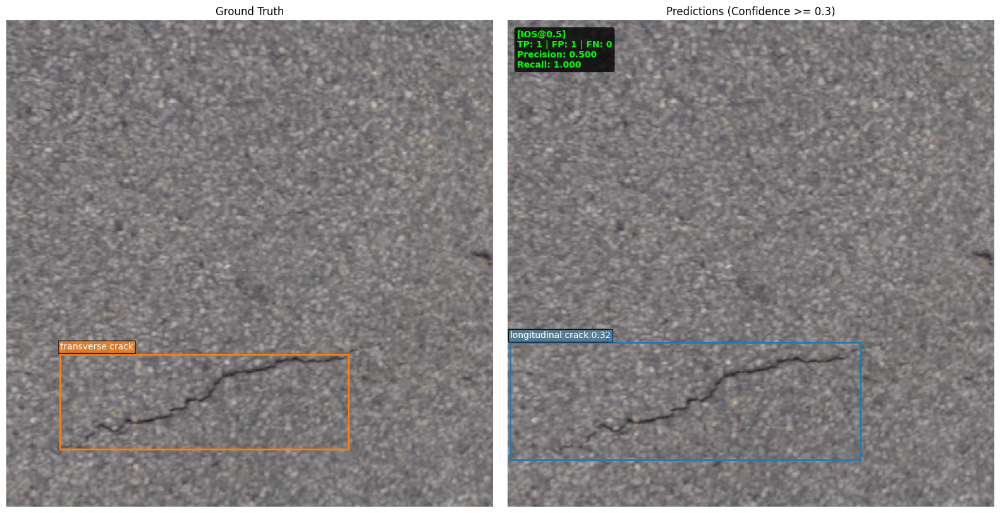

In [10]:
image_evaluator.plot(show=True,show_stats=True,confidence_threshold = 0.3)

## Additional Samples


Image: Japan_004412

--- Metrics for image:  (Conf: 0.3, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.3 |    0 |       1 |    0 |    1 |    0 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


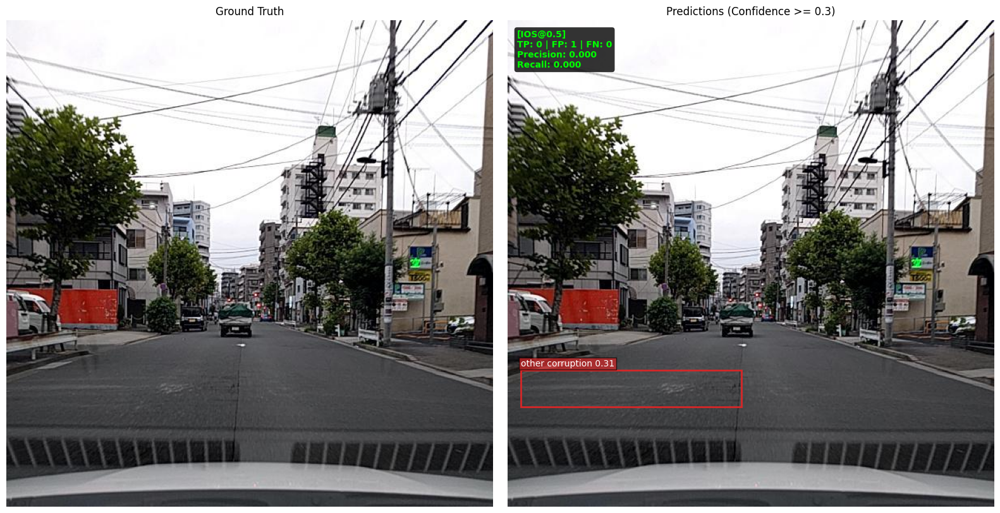


Image: India_005343

--- Metrics for image:  (Conf: 0.3, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.3 |    2 |       3 |    1 |    2 |    1 |      0.3333 |      0.5 |
+------------------+------+---------+------+------+------+-------------+----------+


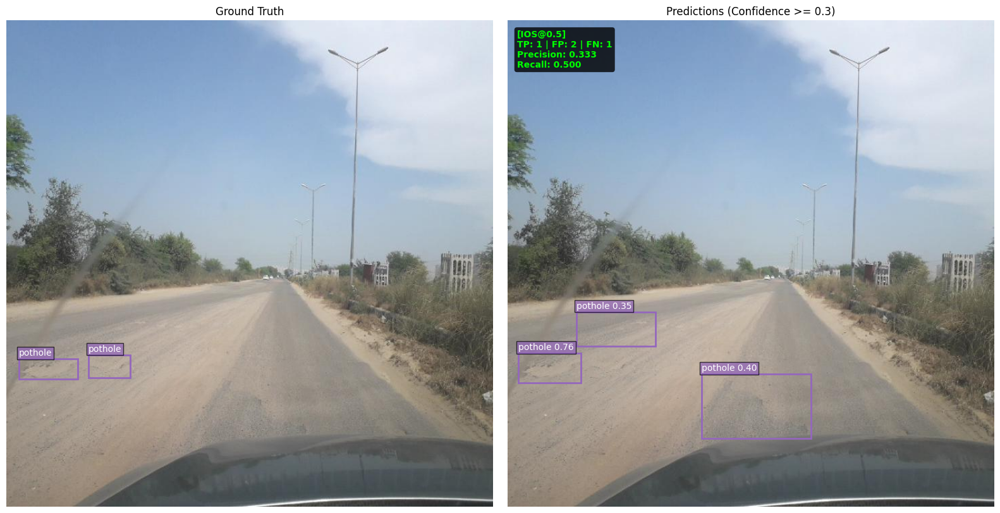


Image: Japan_004174

--- Metrics for image:  (Conf: 0.3, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.3 |    4 |       8 |    3 |    5 |    1 |       0.375 |     0.75 |
+------------------+------+---------+------+------+------+-------------+----------+


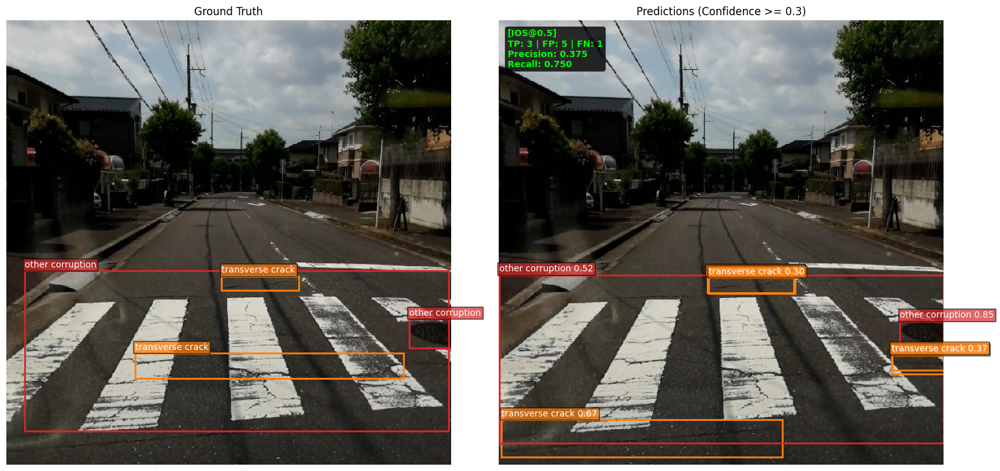

In [11]:
sample_image_ids = pd.Series(list(gt_ids & pred_ids)).sample(n=min(3, len(gt_ids & pred_ids)),random_state=42
).tolist()

for image_id in sample_image_ids:
    print(f"\nImage: {image_id}")

    evaluator = ImageEvaluator(
        gt_path_or_data=GT_DIR / f"{image_id}.json",
        pred_path_or_data=PRED_DIR / f"{image_id}.json",
        threshold=0.5,
        metric_type="ios"
    )

    evaluator.plot(
        confidence_threshold=0.3,
        show=True,
        show_stats = True
    )

## Dataset - Level Evaluation

In [12]:
dataset_evaluator = DatasetEvaluator(
    gt_dir=GT_DIR,
    pred_dir=PRED_DIR,
    metric_type="ios",
)

In [13]:
dataset_evaluator.get_stat(
    confidence_thresholds=[0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9],
    return_stat=True,
    metric_type = "ios",
    threshold=0.5
    
)

Evaluating (IOS): 100%|██████████| 5758/5758 [01:36<00:00, 59.92img/s]



DATASET-LEVEL OVERALL METRICS (IOS@0.5)

+--------------+------+---------------+------+-------+------+-------------+----------+--------+------------+
|   Confidence |   GT |   Predictions |   TP |    FP |   FN |   Precision |   Recall |     F1 |   Mean IOS |
+==============+======+===============+======+=======+======+=============+==========+========+============+
|          0.1 | 9675 |         81687 | 9286 | 72401 |  389 |      0.1137 |   0.9598 | 0.2033 |     0.9327 |
+--------------+------+---------------+------+-------+------+-------------+----------+--------+------------+
|          0.2 | 9675 |         31917 | 8828 | 23089 |  847 |      0.2766 |   0.9125 | 0.4245 |     0.9354 |
+--------------+------+---------------+------+-------+------+-------------+----------+--------+------------+
|          0.3 | 9675 |         18378 | 8297 | 10081 | 1378 |      0.4515 |   0.8576 | 0.5915 |     0.9388 |
+--------------+------+---------------+------+-------+------+-------------+----------+

## Checking the dataset evaluator instance 

In [14]:
print("total dataset images", len(dataset_evaluator.all_image_object))

total dataset images 5758


In [15]:
# print("dataset metrics",dataset_evaluator.results)
# print("overall resutls", dataset_evaluator.overall_df)
# print("per_class_table",dataset_evaluator.per_class_df)
# print("AP score",dataset_evaluator.ap_df)
print("MAP_50 score",dataset_evaluator.results["map_50"])
print("MAP_50:95 score",dataset_evaluator.results["map_50_95"])

MAP_50 score 0.7588484606247763
MAP_50:95 score 0.6838890810364282


In [16]:
sample_image = dataset_evaluator.all_image_object["China_Drone_000017"]
# print(sample_image.results)

In [17]:
dataset_metric_dir = Path("/kaggle/working/rtdetrL_evaluation")
dataset_metric_dir.mkdir(parents=True, exist_ok=True)

In [18]:
dataset_evaluator.overall_df.to_csv(dataset_metric_dir/"overall")

In [19]:
dataset_evaluator.per_class_df.to_csv(dataset_metric_dir/"per_class")

In [20]:
dataset_evaluator.ap_df.to_csv(dataset_metric_dir/"ap_df")

In [21]:
dataset_metric=dataset_evaluator.results

## Conditional filtering in the dataset

Filter matched 195 / 5758 images.

--- Metrics for image: [India_007533] (pothole)  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |    0 |       1 |    0 |    1 |    0 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


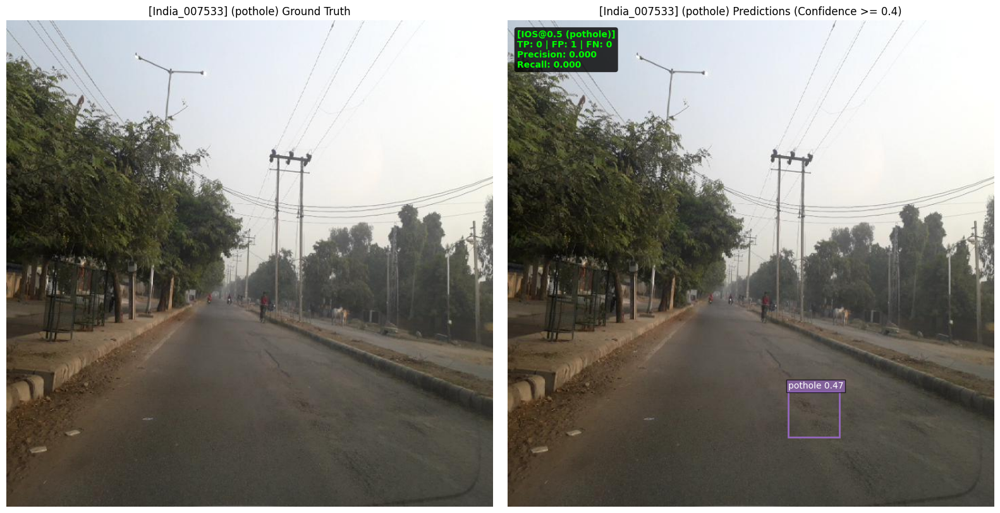


--- Metrics for image: [Japan_009054] (pothole)  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |    1 |       3 |    1 |    2 |    0 |      0.3333 |        1 |
+------------------+------+---------+------+------+------+-------------+----------+


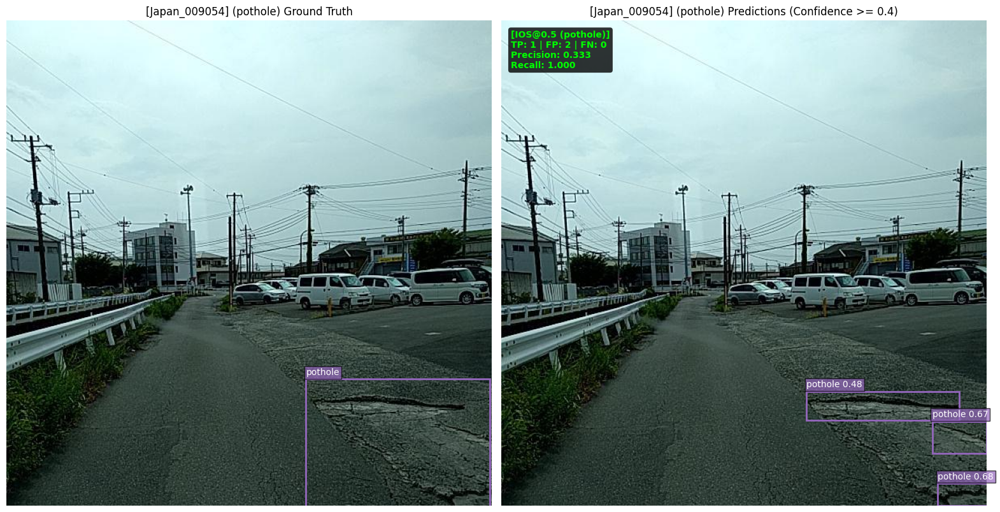


--- Metrics for image: [India_008648] (pothole)  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |    0 |       1 |    0 |    1 |    0 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


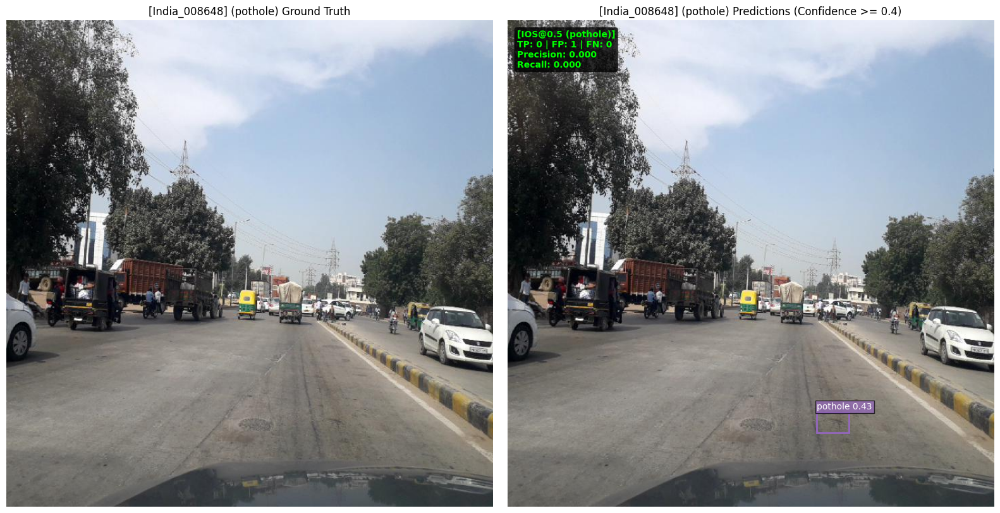


--- Metrics for image: [India_006851] (pothole)  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |    2 |       6 |    2 |    4 |    0 |      0.3333 |        1 |
+------------------+------+---------+------+------+------+-------------+----------+


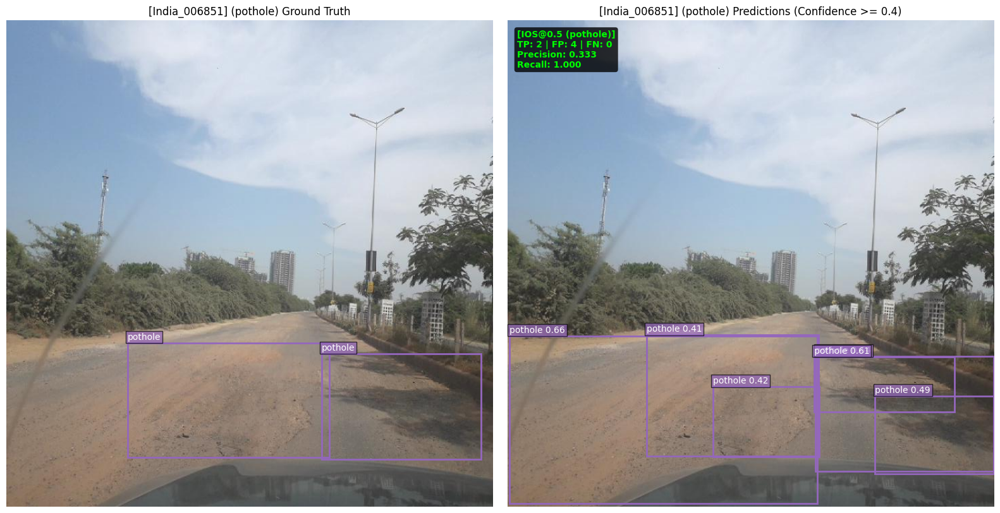


--- Metrics for image: [India_008950] (pothole)  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |    2 |       5 |    2 |    3 |    0 |         0.4 |        1 |
+------------------+------+---------+------+------+------+-------------+----------+


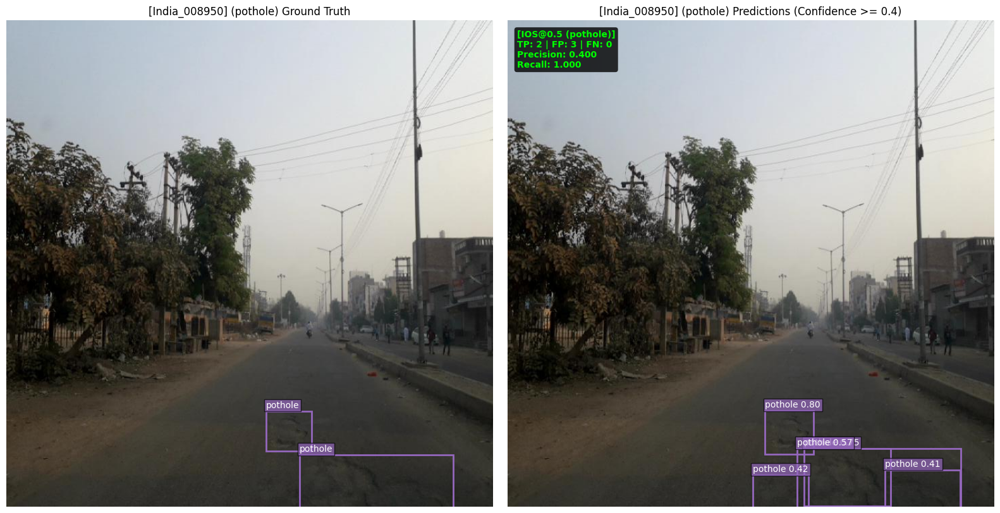

In [22]:
pothole_low_prec_04 = dataset_evaluator.filter(
    class_names="pothole",
    model_confidence_threshold=0.4,
    metric="precision",
    eq="<",
    class_confidence_threshold=0.5
)
pothole_low_prec_04.plot(
    num_samples=5,
    model_confidence_threshold=0.4,
    class_names="pothole",
    show=True,
    show_stats=True
)

Filter matched 324 / 5758 images.

--- Metrics for image: [India_004240] (pothole)  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |    0 |       1 |    0 |    1 |    0 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


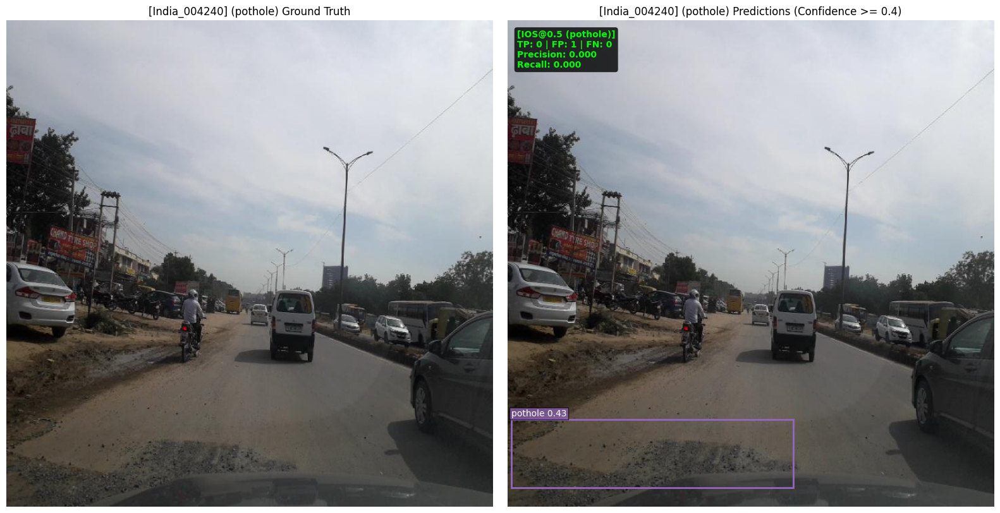


--- Metrics for image: [Czech_000816] (pothole)  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |    0 |       1 |    0 |    1 |    0 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


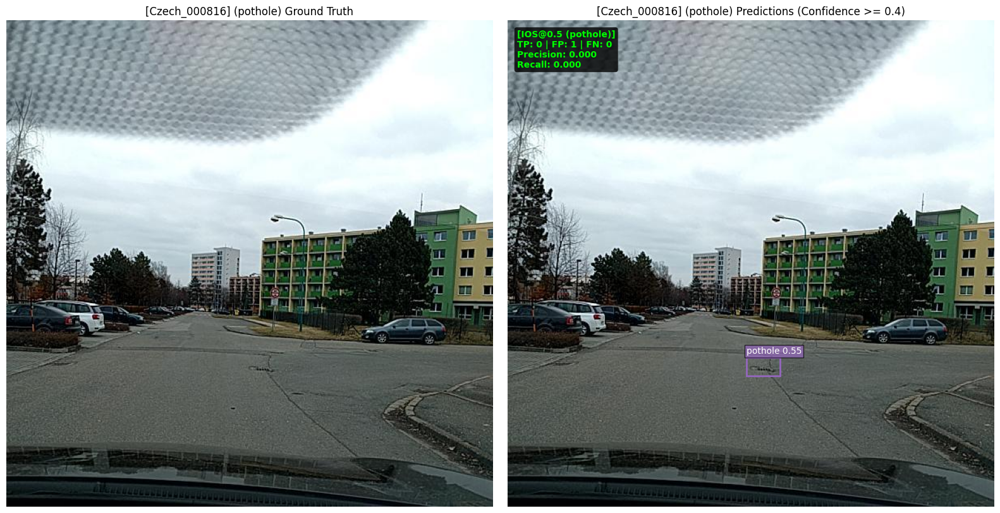


--- Metrics for image: [Japan_012995] (pothole)  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |    0 |       1 |    0 |    1 |    0 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


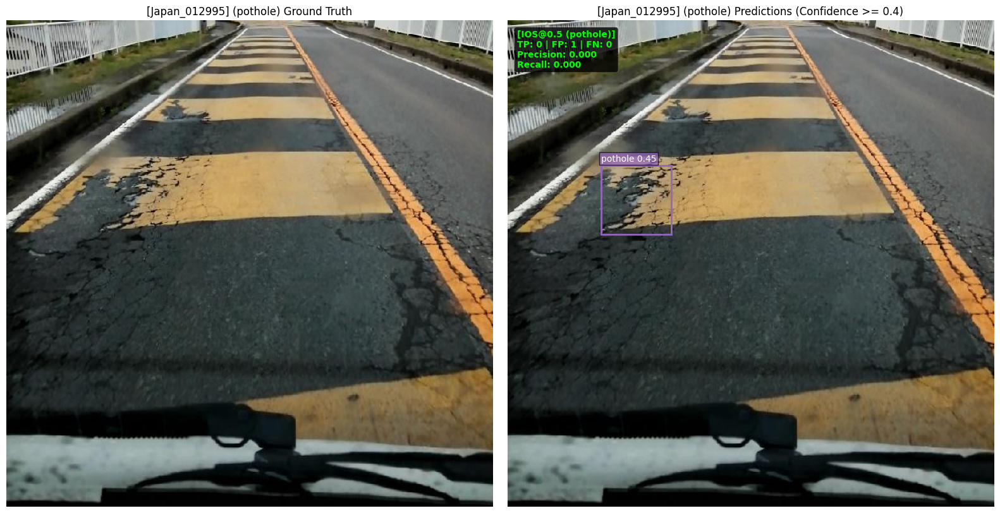


--- Metrics for image: [Japan_002133] (pothole)  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |    2 |       3 |    2 |    1 |    0 |      0.6667 |        1 |
+------------------+------+---------+------+------+------+-------------+----------+


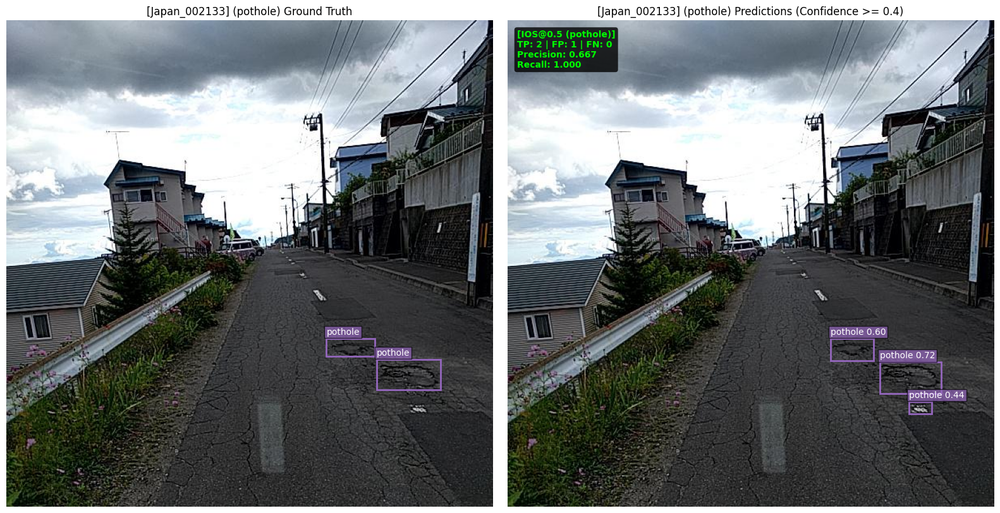


--- Metrics for image: [India_001953] (pothole)  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |    0 |       1 |    0 |    1 |    0 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


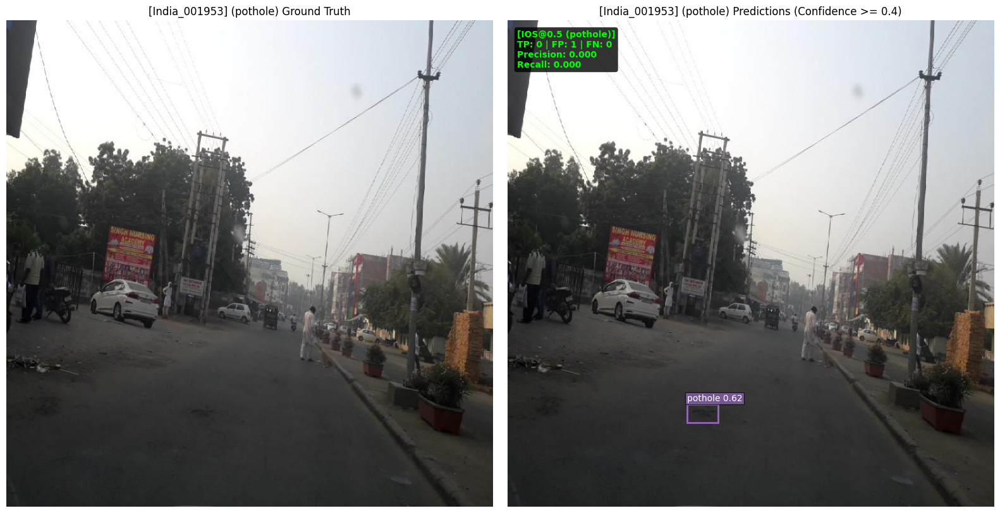

In [23]:
# B. Direct FP vs. FN count comparison for pothole at 0.4
pothole_fp_04 = dataset_evaluator.filter(
    class_names="pothole",
    model_confidence_threshold=0.4,
    metric="fp",
    eq=">",
    class_confidence_threshold=0
)
pothole_fp_04.plot(
    num_samples=5,
    model_confidence_threshold=0.4,
    class_names="pothole",
    show=True,
    show_stats=True
)


Filter matched 215 / 5758 images.

--- Metrics for image: [Japan_006824] (pothole)  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |    5 |       3 |    3 |    0 |    2 |           1 |      0.6 |
+------------------+------+---------+------+------+------+-------------+----------+


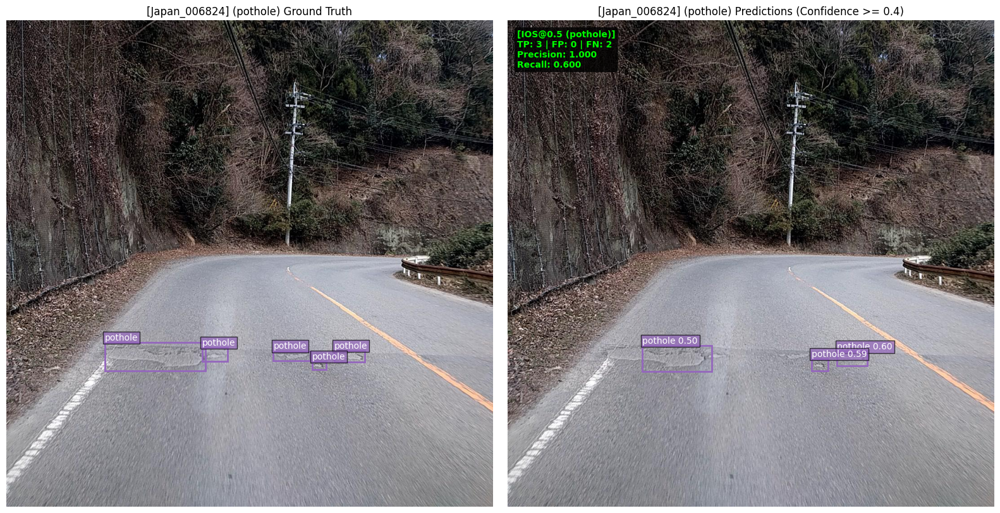


--- Metrics for image: [India_001877] (pothole)  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |    2 |       1 |    1 |    0 |    1 |           1 |      0.5 |
+------------------+------+---------+------+------+------+-------------+----------+


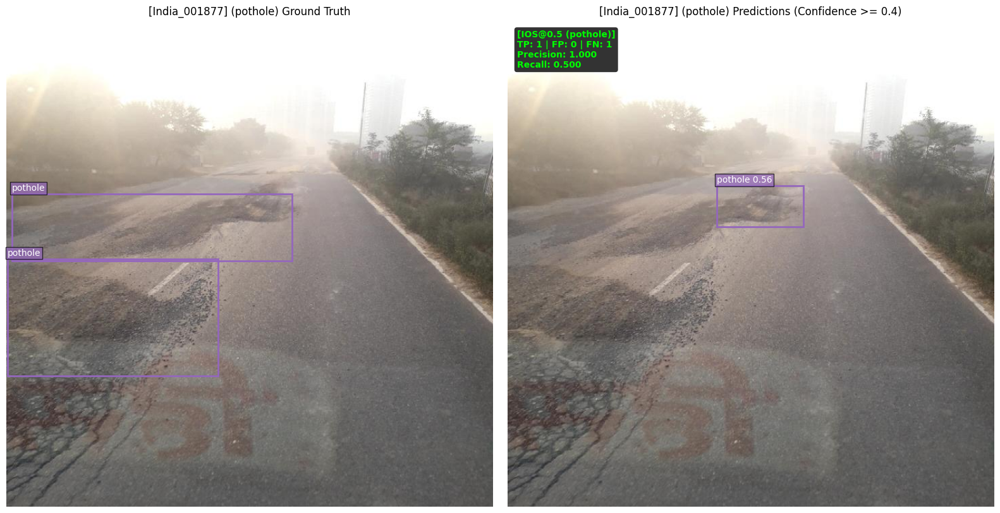


--- Metrics for image: [Japan_012888] (pothole)  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |    7 |       6 |    6 |    0 |    1 |           1 |   0.8571 |
+------------------+------+---------+------+------+------+-------------+----------+


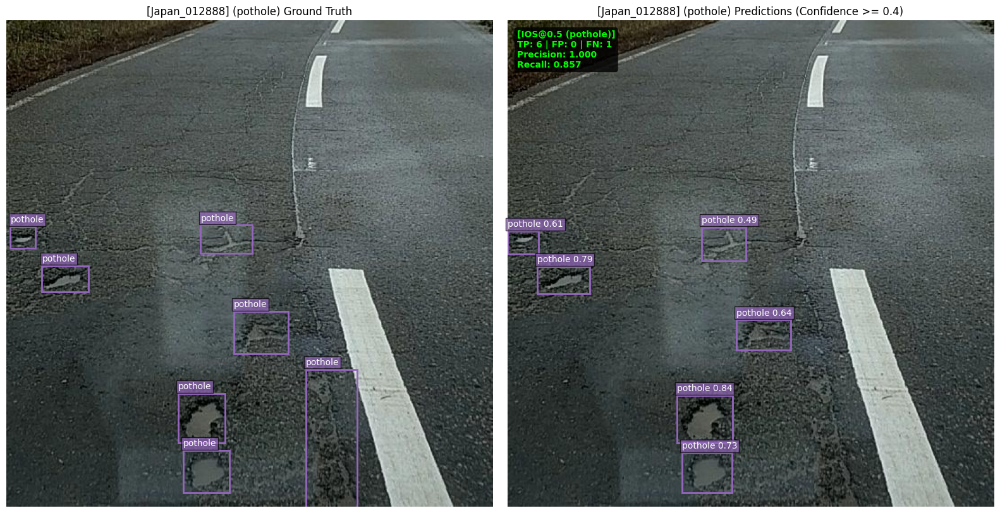


--- Metrics for image: [Japan_012108] (pothole)  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |    3 |       2 |    2 |    0 |    1 |           1 |   0.6667 |
+------------------+------+---------+------+------+------+-------------+----------+


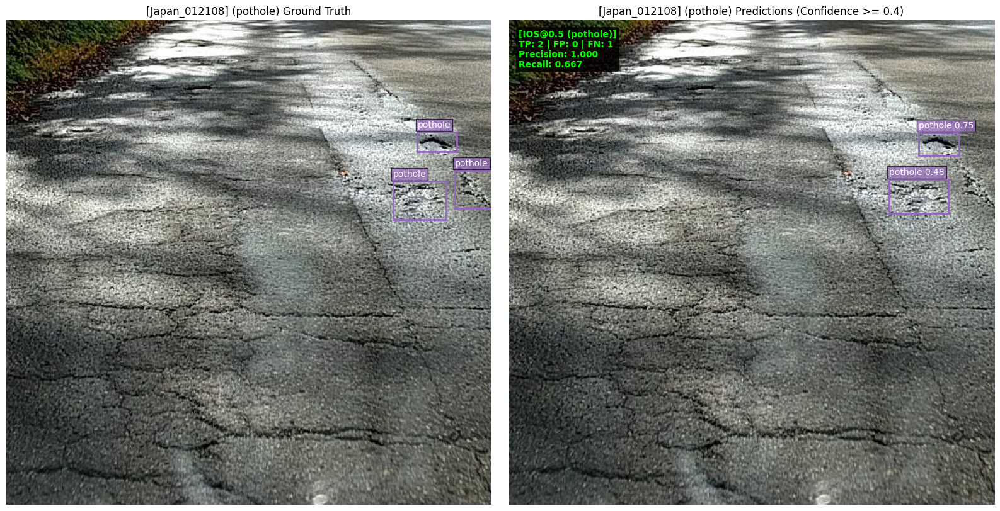


--- Metrics for image: [India_000517] (pothole)  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |    4 |       4 |    3 |    1 |    1 |        0.75 |     0.75 |
+------------------+------+---------+------+------+------+-------------+----------+


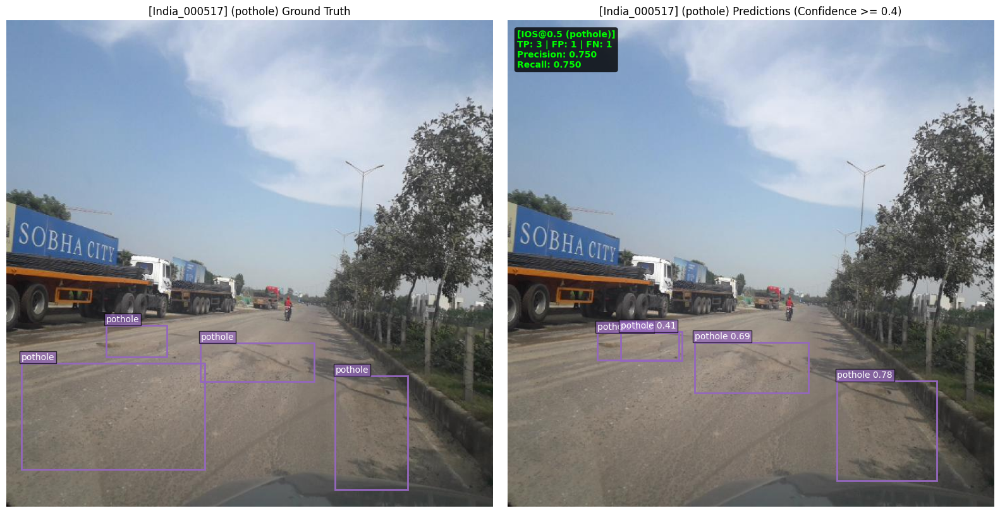

In [24]:
pothole_fn_04 = dataset_evaluator.filter(
    class_names="pothole",
    model_confidence_threshold=0.4,
    metric="fn",
    eq=">",
    class_confidence_threshold=0
)
pothole_fn_04.plot(
    num_samples=5,
    model_confidence_threshold=0.4,
    class_names="pothole",
    show=True,
    show_stats=True
)

Filter matched 317 / 5758 images.

--- Metrics for image: [China_Drone_000268] (transverse crack)  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |    1 |       0 |    0 |    0 |    1 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


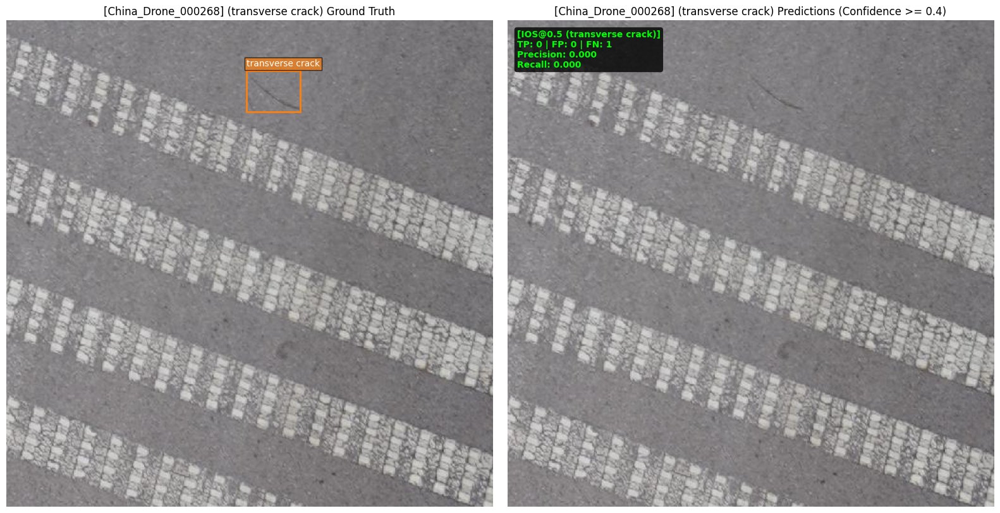


--- Metrics for image: [China_Drone_000852] (transverse crack)  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |    2 |       2 |    1 |    1 |    1 |         0.5 |      0.5 |
+------------------+------+---------+------+------+------+-------------+----------+


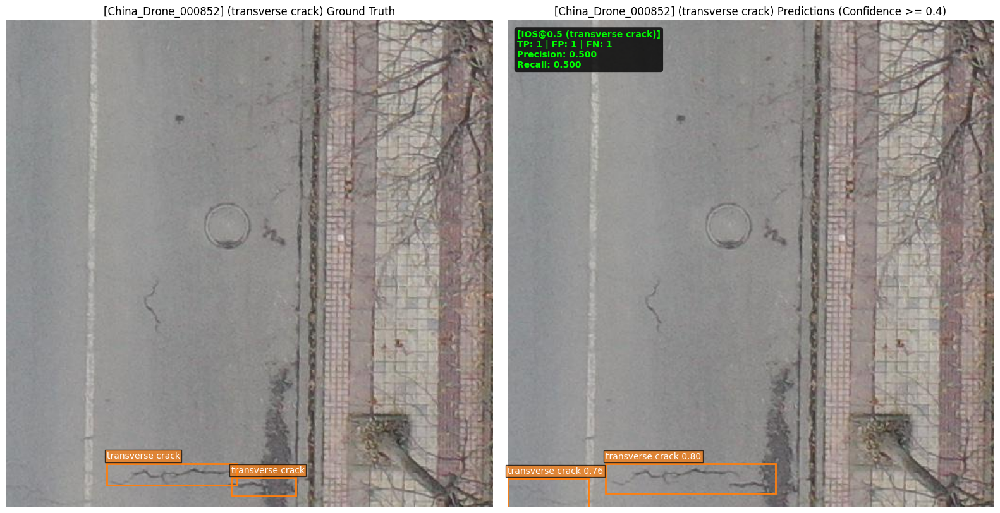


--- Metrics for image: [China_Drone_000918] (transverse crack)  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |    1 |       0 |    0 |    0 |    1 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


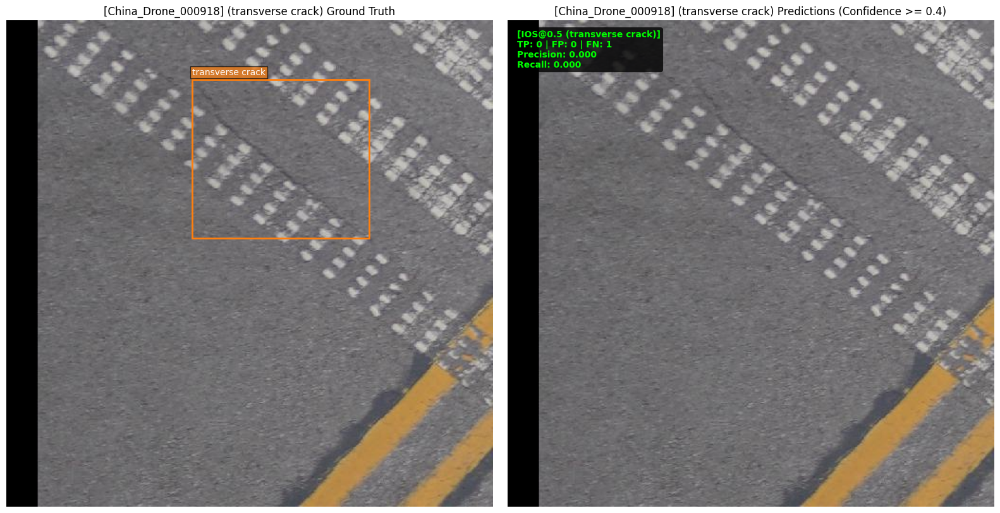


--- Metrics for image: [China_Drone_001143] (transverse crack)  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |    3 |       2 |    2 |    0 |    1 |           1 |   0.6667 |
+------------------+------+---------+------+------+------+-------------+----------+


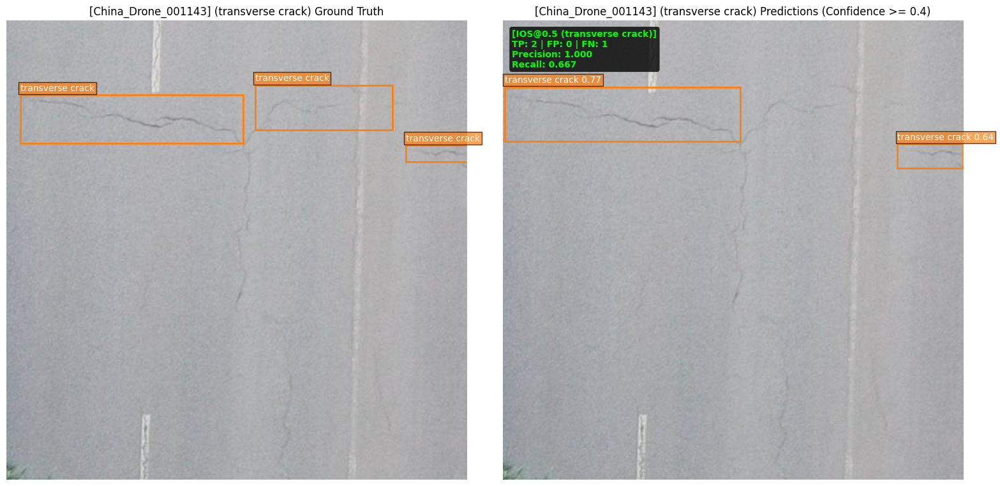


--- Metrics for image: [China_Drone_001149] (transverse crack)  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |    2 |       1 |    1 |    0 |    1 |           1 |      0.5 |
+------------------+------+---------+------+------+------+-------------+----------+


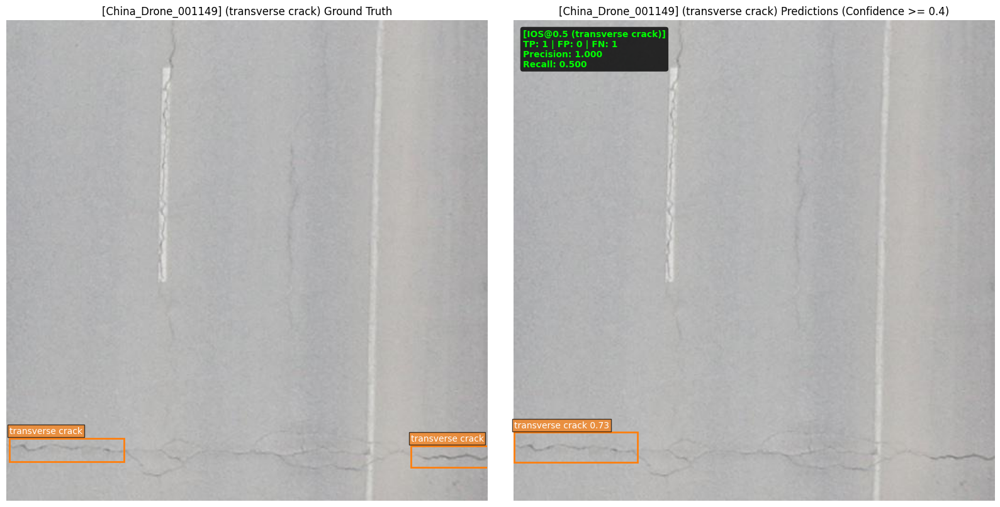

In [25]:
transverse_fn_04 = dataset_evaluator.filter(
    class_names="transverse crack",      
    model_confidence_threshold=0.4,
    metric="fn",
    eq=">",
    class_confidence_threshold=0
)

# 2. Plot those images showing ONLY transverse crack boxes and stats
transverse_fn_04.plot(
    num_samples=5,
    model_confidence_threshold=0.4,
    class_names="transverse crack",      # Keeps other classes hidden for clean inspection
    random_sample=False,                 # Set False to inspect in deterministic order
    show=True,
    show_stats=True
)

Filter matched 413 / 5758 images.

--- Metrics for image: [China_Drone_000052] (transverse crack)  (Conf: 0.5, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.5 |    1 |       0 |    0 |    0 |    1 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


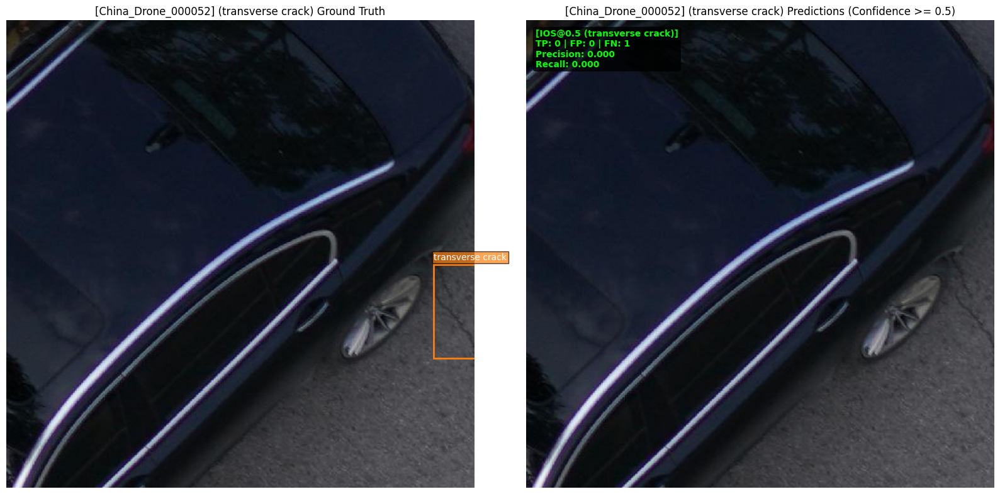


--- Metrics for image: [China_Drone_000268] (transverse crack)  (Conf: 0.5, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.5 |    1 |       0 |    0 |    0 |    1 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


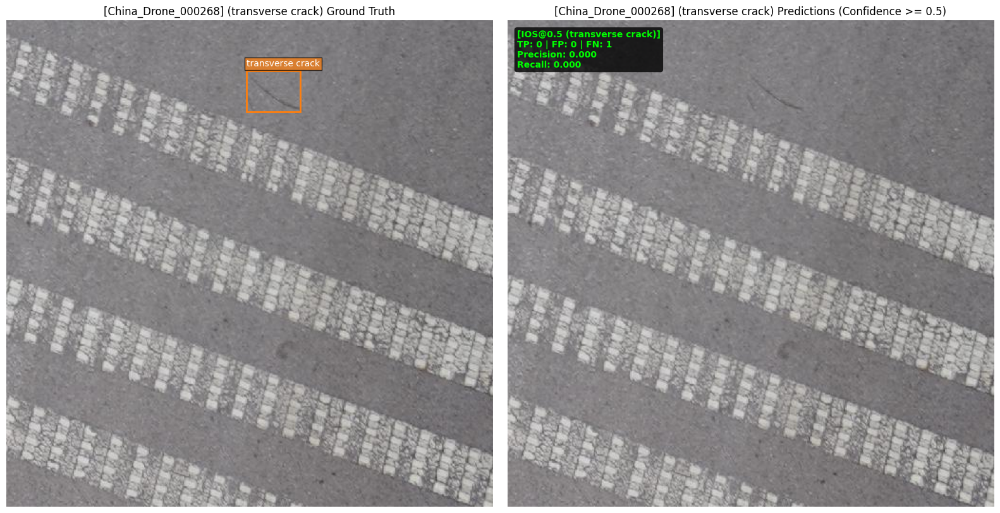


--- Metrics for image: [China_Drone_000772] (transverse crack)  (Conf: 0.5, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.5 |    1 |       0 |    0 |    0 |    1 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


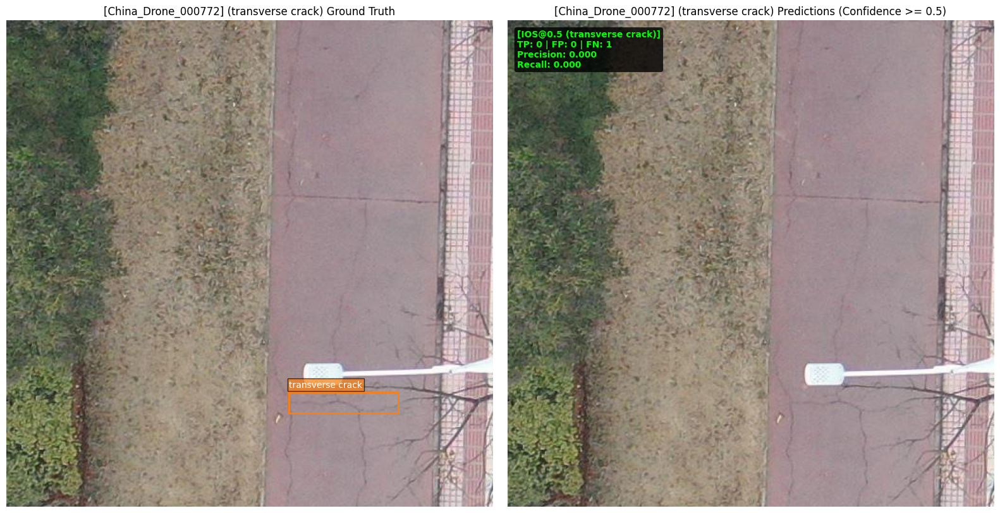


--- Metrics for image: [China_Drone_000791] (transverse crack)  (Conf: 0.5, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.5 |    1 |       0 |    0 |    0 |    1 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


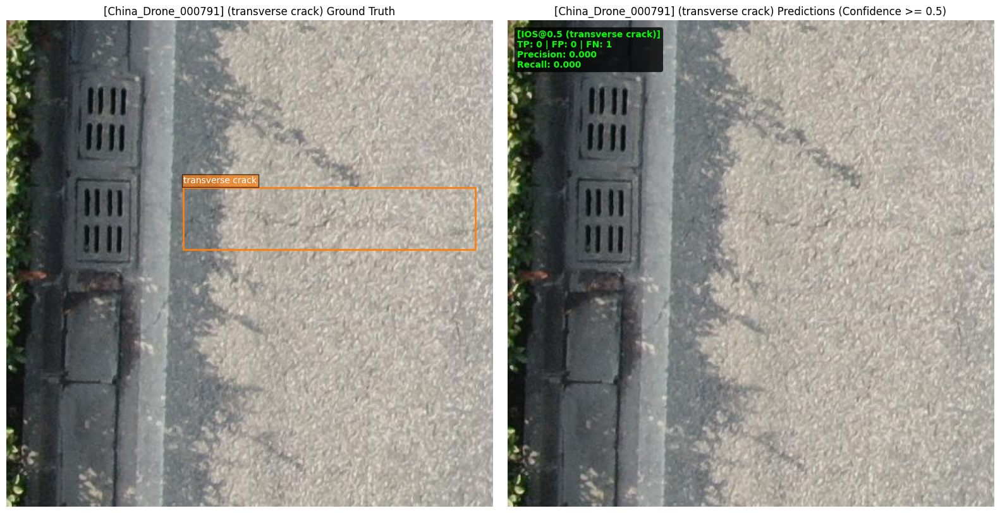


--- Metrics for image: [China_Drone_000852] (transverse crack)  (Conf: 0.5, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.5 |    2 |       2 |    1 |    1 |    1 |         0.5 |      0.5 |
+------------------+------+---------+------+------+------+-------------+----------+


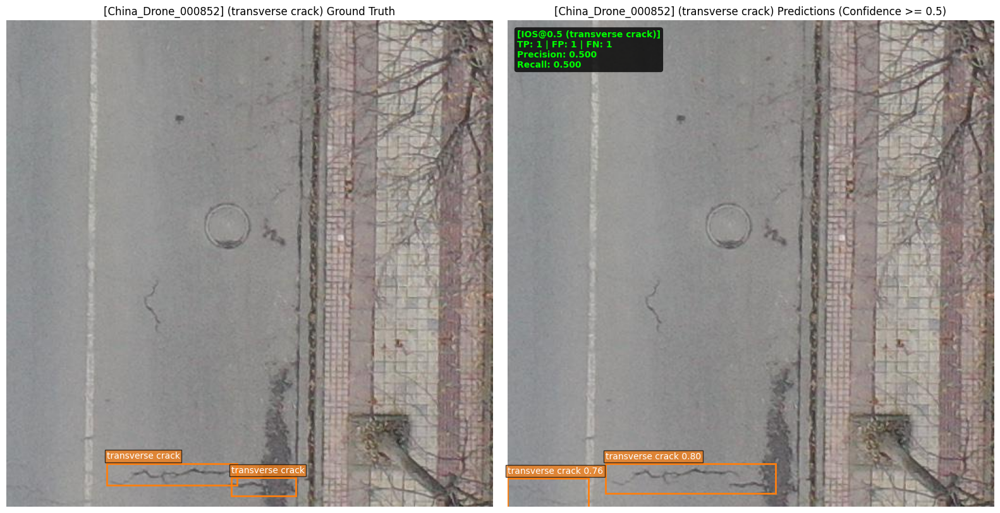

In [26]:
transverse_fn_05 = dataset_evaluator.filter(
    class_names="transverse crack",      
    model_confidence_threshold=0.5,
    metric="fn",
    eq=">",
    class_confidence_threshold=0
)

# 2. Plot those images showing ONLY transverse crack boxes and stats
transverse_fn_05.plot(
    num_samples=5,
    model_confidence_threshold=0.5,
    class_names="transverse crack",      # Keeps other classes hidden for clean inspection
    random_sample=False,                 # Set False to inspect in deterministic order
    show=True,
    show_stats=True
)

Filter matched 2595 / 5758 images.

--- Metrics for image: [United_States_004564]  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |    1 |       2 |    1 |    1 |    0 |         0.5 |        1 |
+------------------+------+---------+------+------+------+-------------+----------+


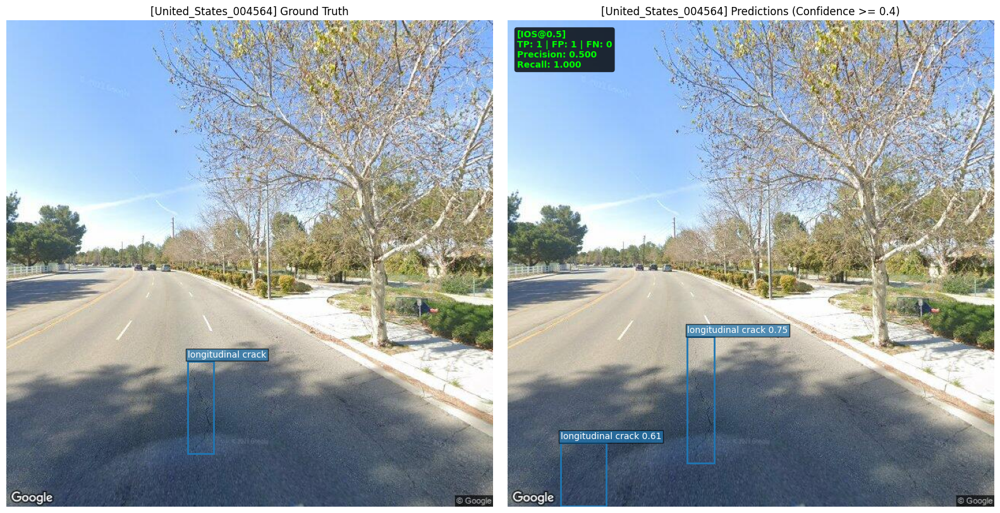


--- Metrics for image: [China_Drone_001717]  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |    3 |       5 |    0 |    5 |    3 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


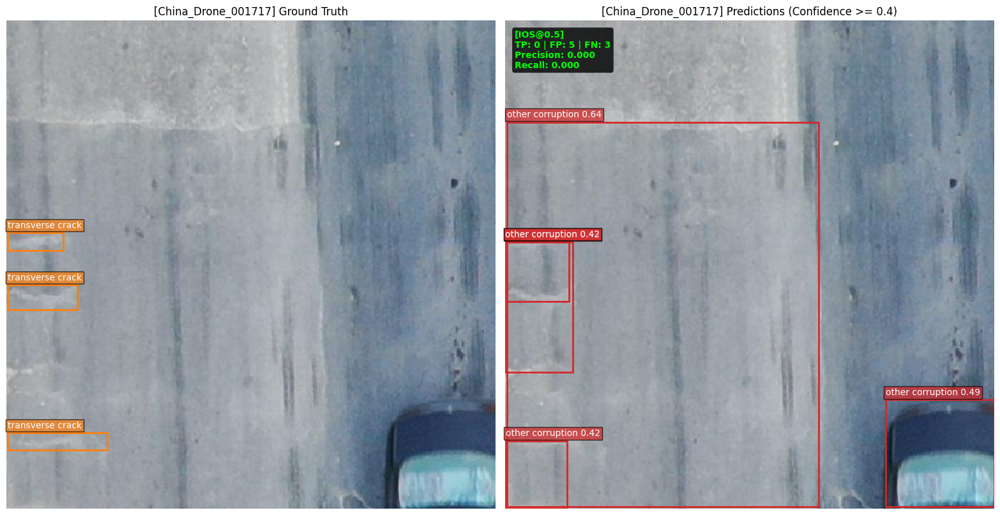


--- Metrics for image: [United_States_001241]  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |    4 |       4 |    3 |    1 |    1 |        0.75 |     0.75 |
+------------------+------+---------+------+------+------+-------------+----------+


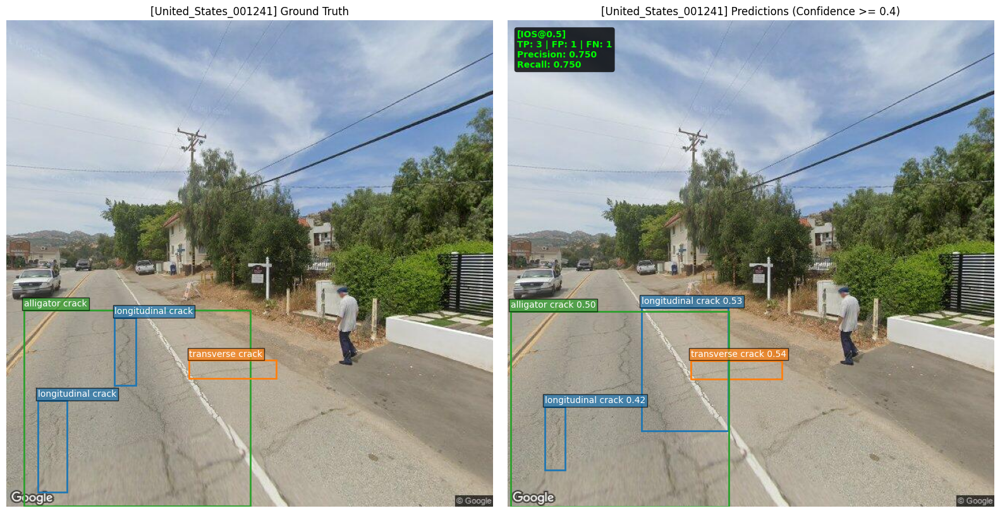


--- Metrics for image: [Japan_011609]  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |    2 |       1 |    0 |    1 |    2 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


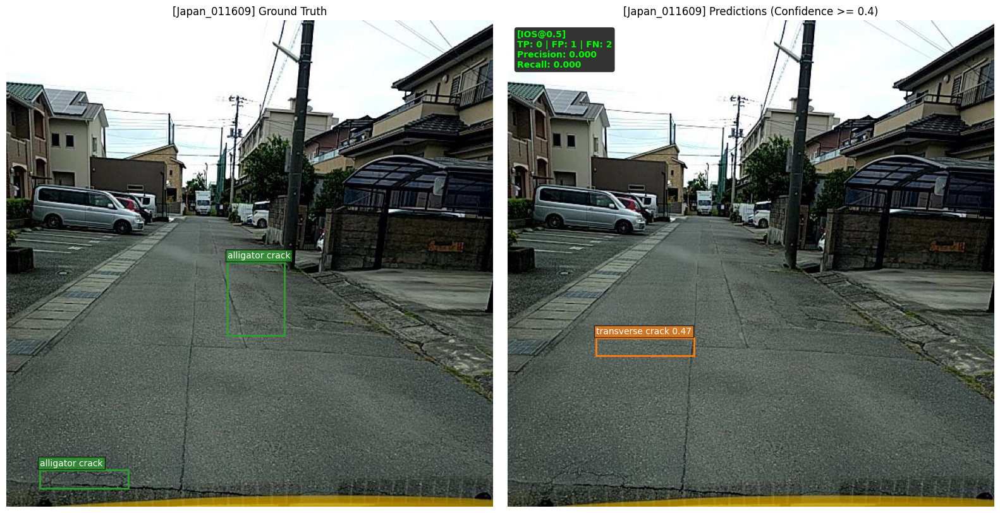


--- Metrics for image: [China_Drone_000311]  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |    1 |       2 |    1 |    1 |    0 |         0.5 |        1 |
+------------------+------+---------+------+------+------+-------------+----------+


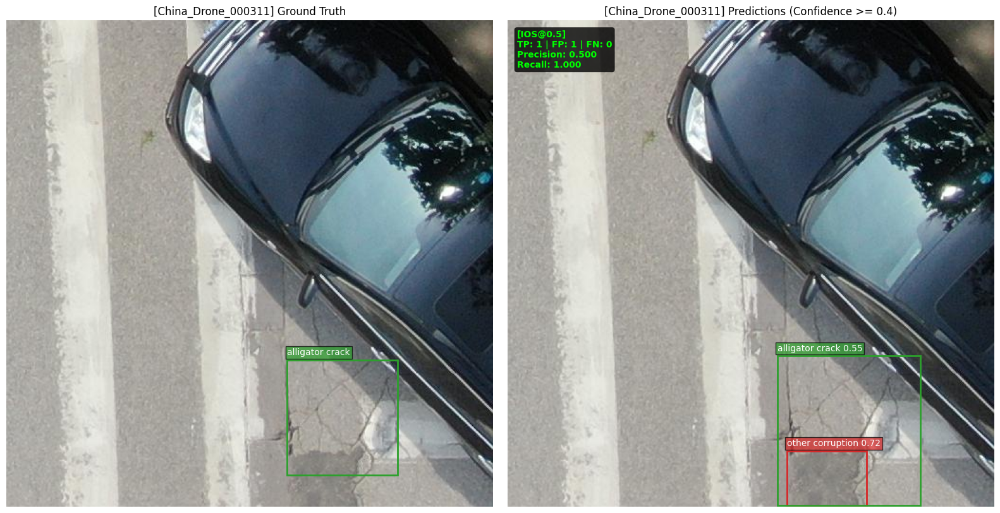

In [27]:


# A. All-class False Positives at 0.4
all_fp_04 = dataset_evaluator.filter(
    class_names = ["longitudinal crack","transverse crack","alligator crack","other corruption","pothole"],
    model_confidence_threshold=0.4,
    metric="fp",
    eq=">",
    class_confidence_threshold=0
)
all_fp_04.plot(
    num_samples=5,
    model_confidence_threshold=0.4,
    show=True,
    show_stats=True
)



Filter matched 1142 / 5758 images.

--- Metrics for image: [China_Drone_001534]  (Conf: 0.5, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.5 |    3 |       2 |    1 |    1 |    2 |         0.5 |   0.3333 |
+------------------+------+---------+------+------+------+-------------+----------+


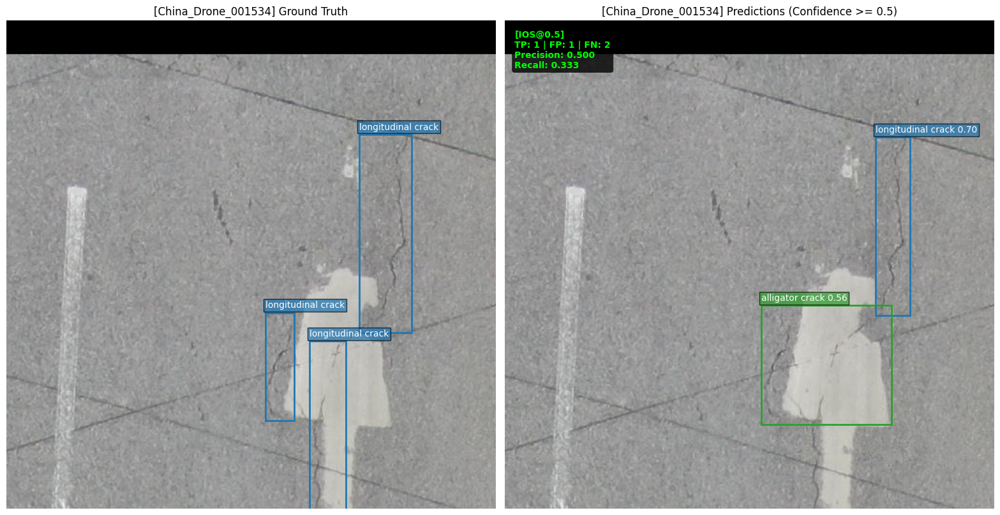


--- Metrics for image: [Japan_005824]  (Conf: 0.5, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.5 |    4 |       3 |    2 |    1 |    2 |      0.6667 |      0.5 |
+------------------+------+---------+------+------+------+-------------+----------+


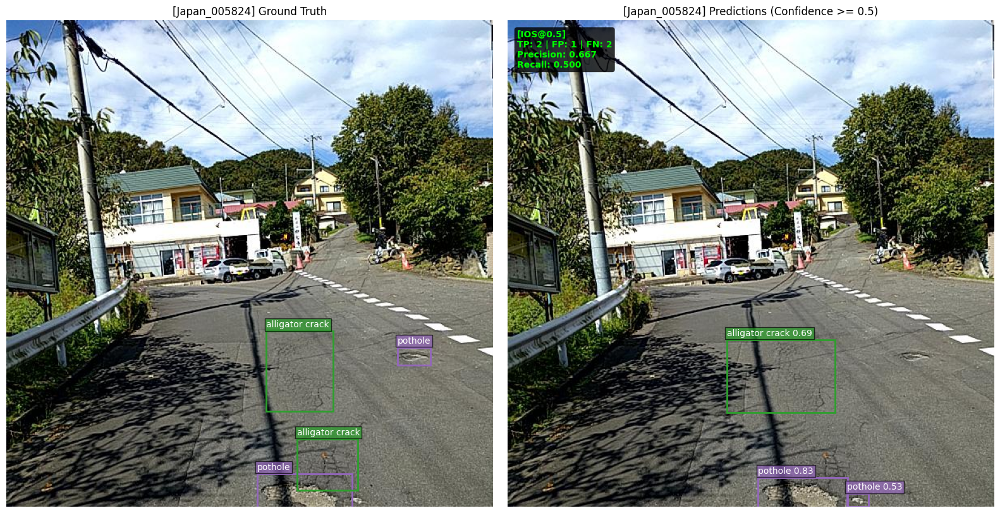


--- Metrics for image: [China_MotorBike_000764]  (Conf: 0.5, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.5 |    4 |       9 |    4 |    5 |    0 |      0.4444 |        1 |
+------------------+------+---------+------+------+------+-------------+----------+


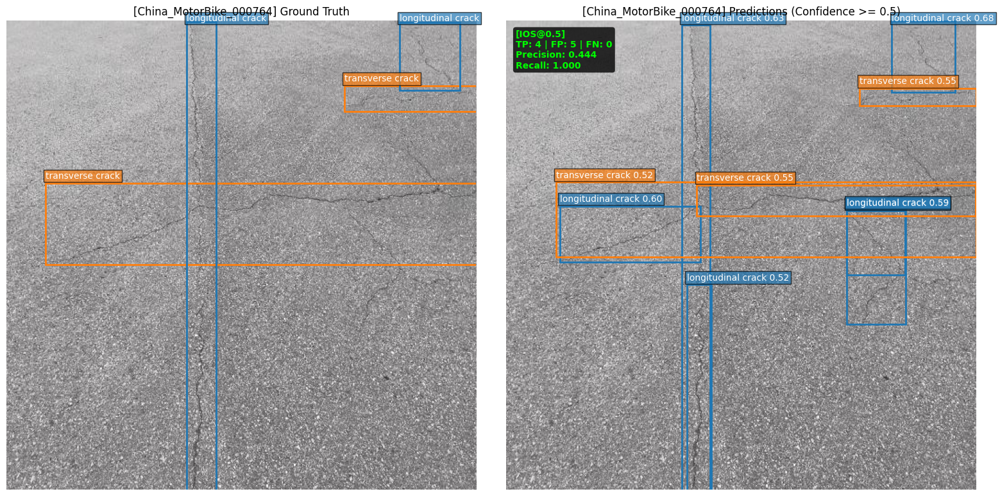


--- Metrics for image: [Japan_003351]  (Conf: 0.5, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.5 |    1 |       2 |    1 |    1 |    0 |         0.5 |        1 |
+------------------+------+---------+------+------+------+-------------+----------+


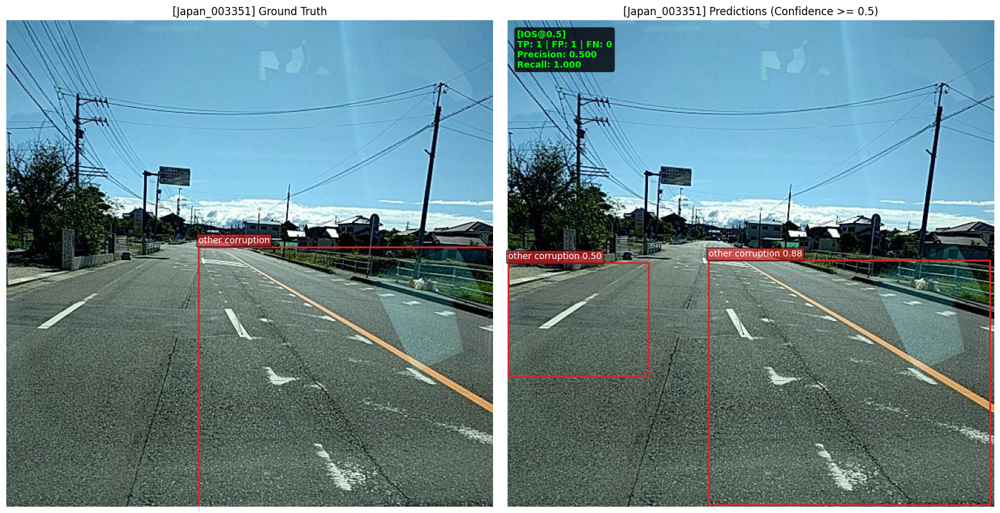


--- Metrics for image: [Czech_000786]  (Conf: 0.5, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.5 |    2 |       2 |    1 |    1 |    1 |         0.5 |      0.5 |
+------------------+------+---------+------+------+------+-------------+----------+


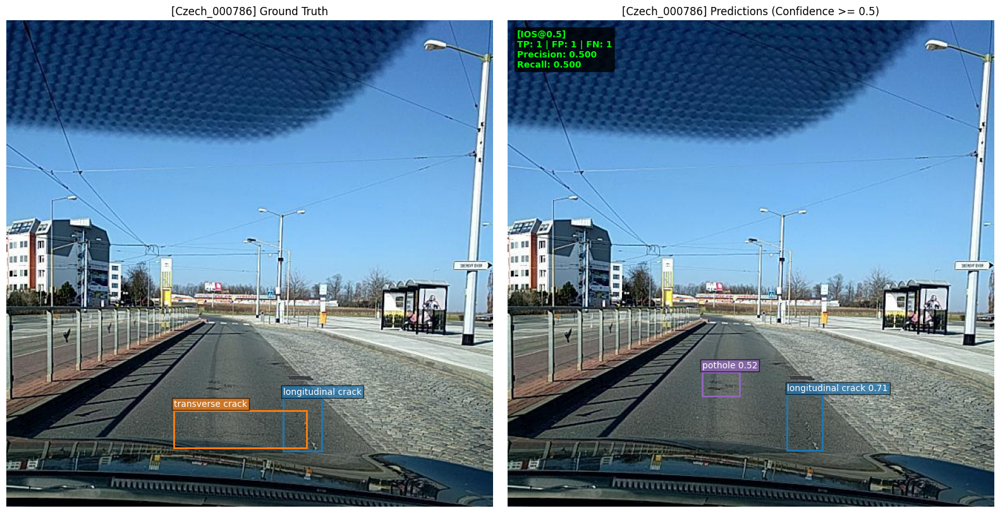

In [28]:
### B. All-class False Positives at 0.5
all_fp_05 = dataset_evaluator.filter(
    class_names=["longitudnal crack","transverse crack","alligator crack","other corruption","pothole"],
    model_confidence_threshold=0.5,
    metric="fp",
    eq=">",
    class_confidence_threshold=0
)
all_fp_05.plot(
    num_samples=5,
    model_confidence_threshold=0.5,
    show=True,
    show_stats=True
)

Filter matched 381 / 5758 images.

--- Metrics for image: [Japan_007781]  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |    1 |       1 |    0 |    1 |    1 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


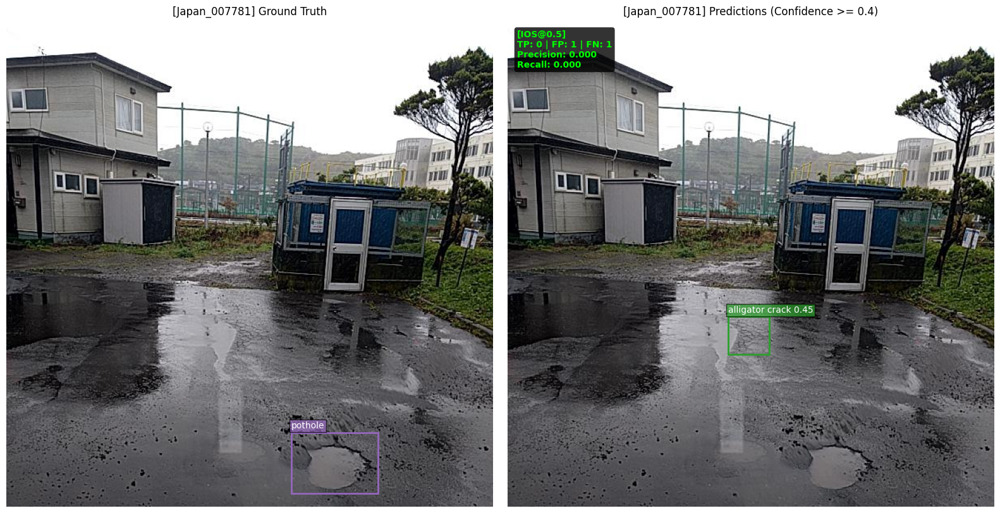


--- Metrics for image: [India_009555]  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |    1 |       0 |    0 |    0 |    1 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


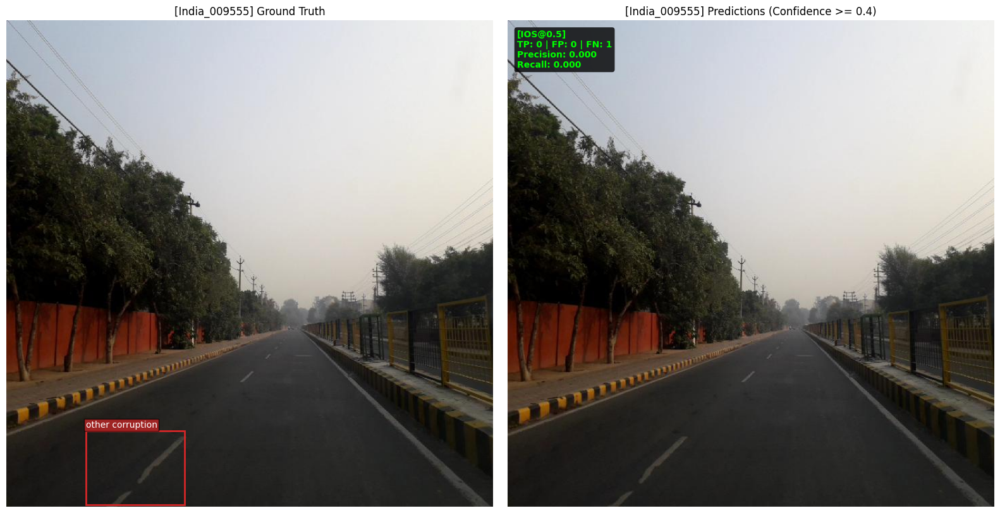


--- Metrics for image: [Norway_002367]  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |    2 |       1 |    0 |    1 |    2 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


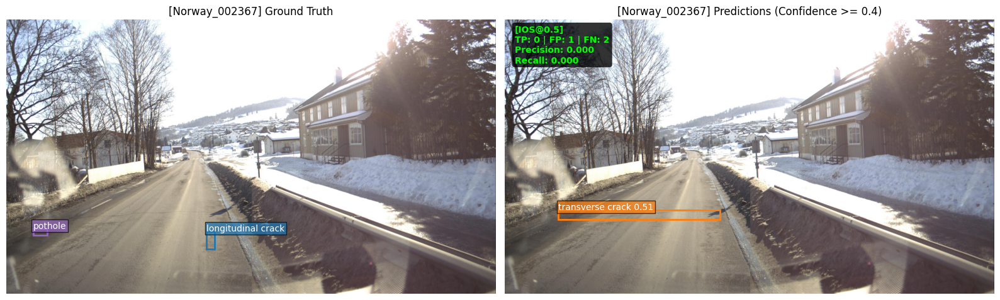


--- Metrics for image: [Japan_011406]  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |    3 |       3 |    1 |    2 |    2 |      0.3333 |   0.3333 |
+------------------+------+---------+------+------+------+-------------+----------+


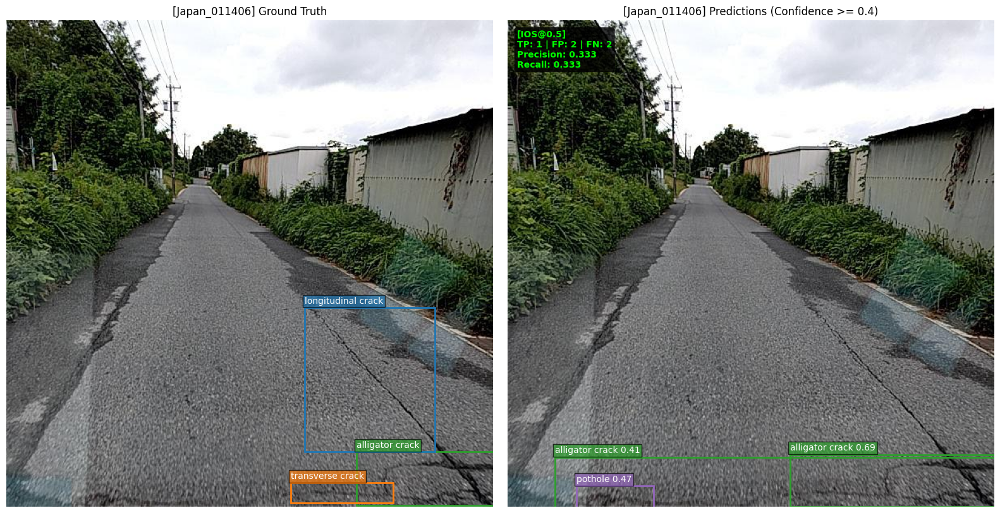


--- Metrics for image: [Japan_003268]  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |    4 |       1 |    1 |    0 |    3 |           1 |     0.25 |
+------------------+------+---------+------+------+------+-------------+----------+


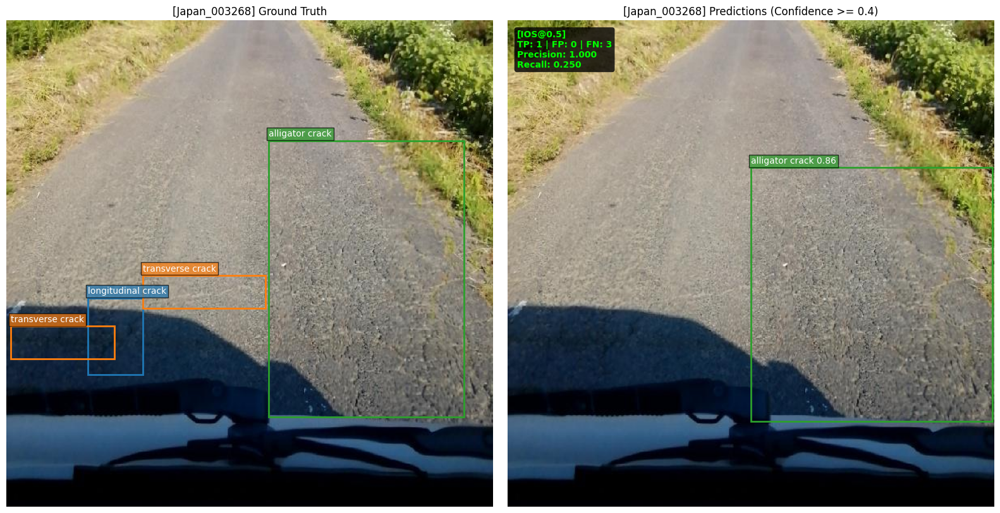

In [29]:
complete_misses = dataset_evaluator.filter(
    class_names=["longitudnal crack","transverse crack","alligstor crack","other corruption","pothole"],
    model_confidence_threshold=0.4,
    metric="recall",
    eq="==",
    class_confidence_threshold=0.0
)
complete_misses.plot(num_samples=5, model_confidence_threshold=0.4, show=True, show_stats=True)

Filter matched 156 / 5758 images.

--- Metrics for image: [India_009666]  (Conf: 0.75, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|             0.75 |    2 |       2 |    1 |    1 |    1 |         0.5 |      0.5 |
+------------------+------+---------+------+------+------+-------------+----------+


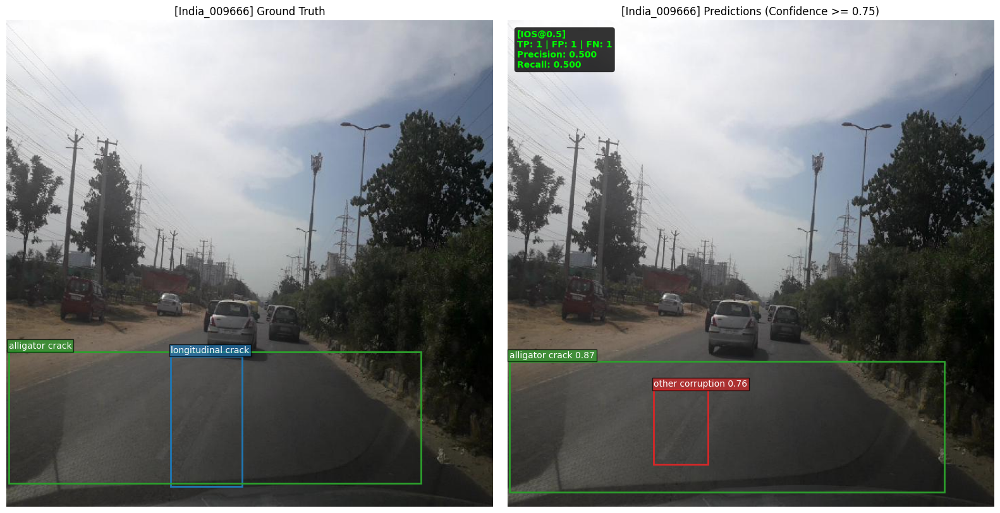


--- Metrics for image: [United_States_000479]  (Conf: 0.75, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|             0.75 |    4 |       2 |    1 |    1 |    3 |         0.5 |     0.25 |
+------------------+------+---------+------+------+------+-------------+----------+


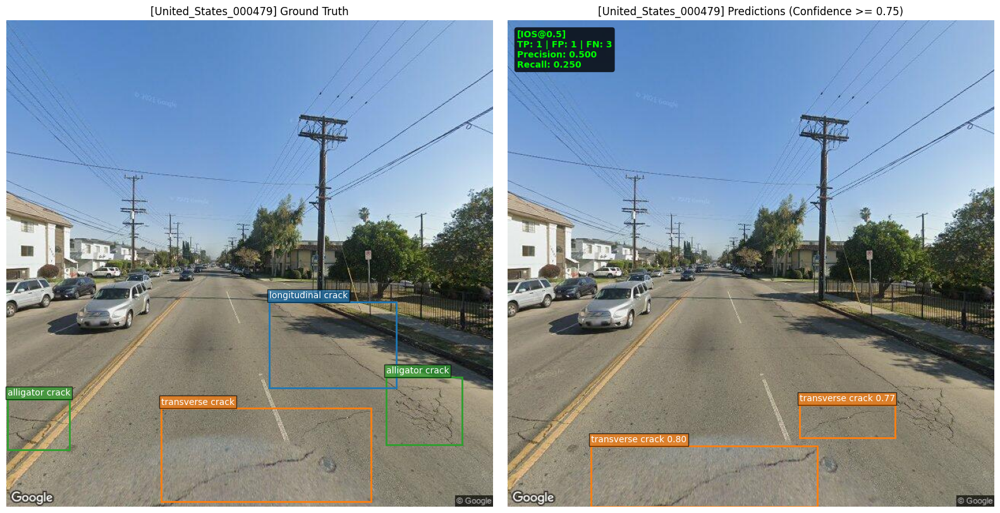


--- Metrics for image: [Japan_008964]  (Conf: 0.75, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|             0.75 |    1 |       1 |    0 |    1 |    1 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


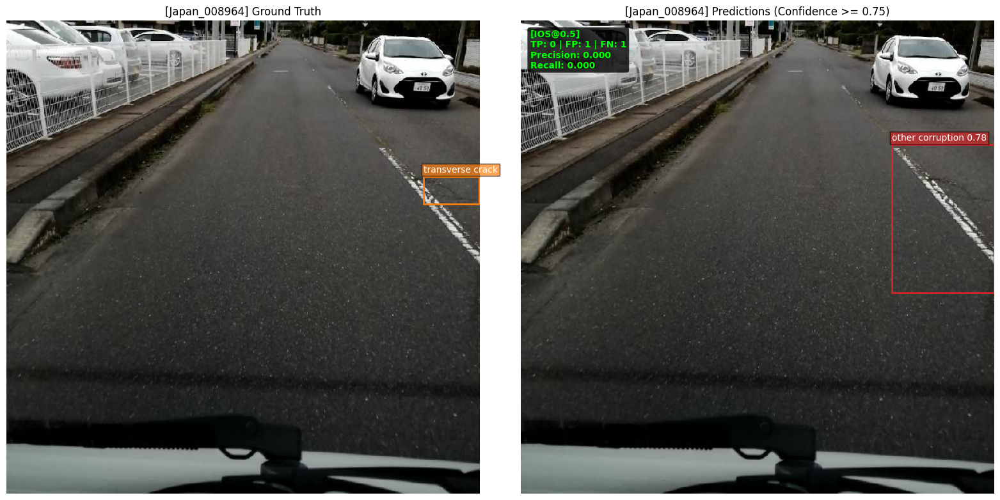


--- Metrics for image: [Japan_001715]  (Conf: 0.75, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|             0.75 |    1 |       1 |    0 |    1 |    1 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


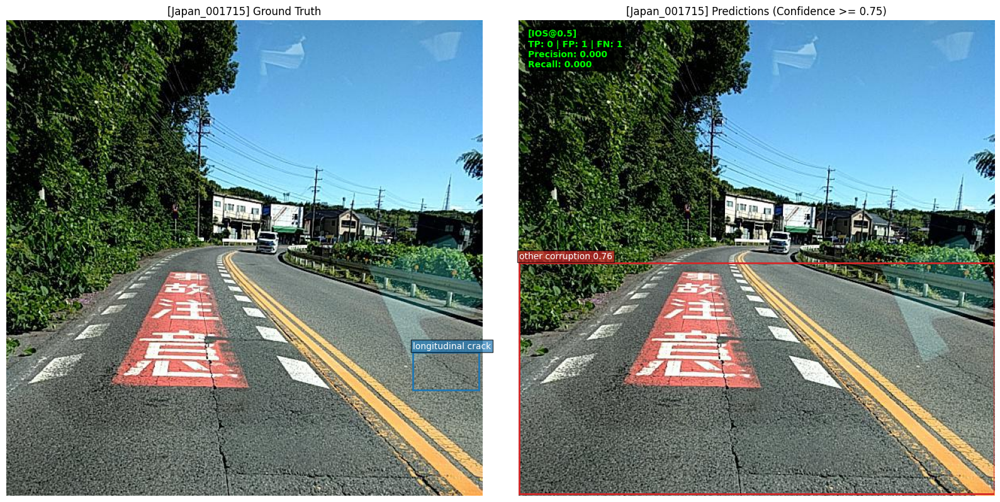


--- Metrics for image: [Japan_004242]  (Conf: 0.75, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|             0.75 |    2 |       1 |    0 |    1 |    2 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


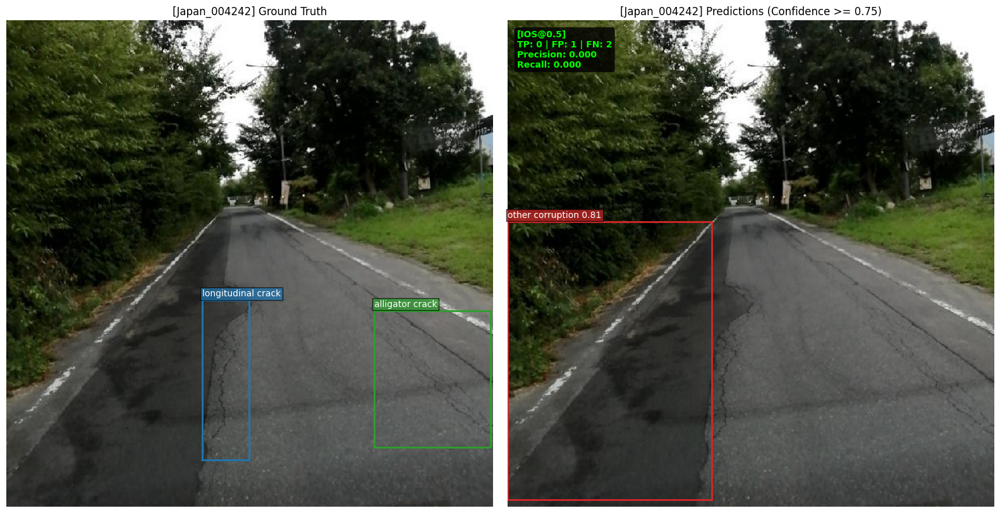

In [30]:
high_conf_hallucinations = dataset_evaluator.filter(
    class_names=["longitudnal crack","transverse crack","alligator crack","other corruption","pothole"],
    model_confidence_threshold=0.75,
    metric="fp",
    eq=">",
    class_confidence_threshold=0
)
high_conf_hallucinations.plot(num_samples=5, model_confidence_threshold=0.75, show=True, show_stats=True)

Filter matched 1023 / 5758 images.

--- Metrics for image: [Japan_001973]  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |    0 |       1 |    0 |    1 |    0 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


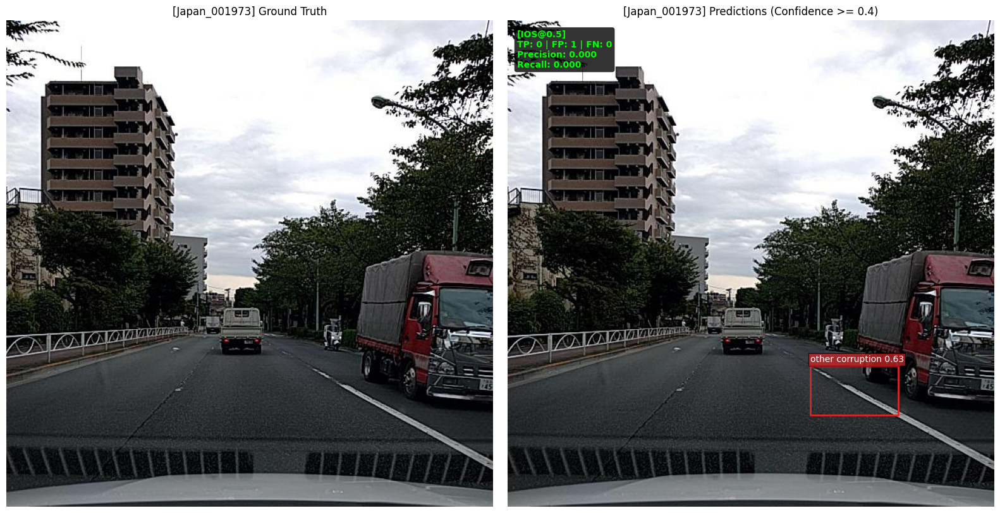


--- Metrics for image: [Czech_002900]  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |    2 |       2 |    1 |    1 |    1 |         0.5 |      0.5 |
+------------------+------+---------+------+------+------+-------------+----------+


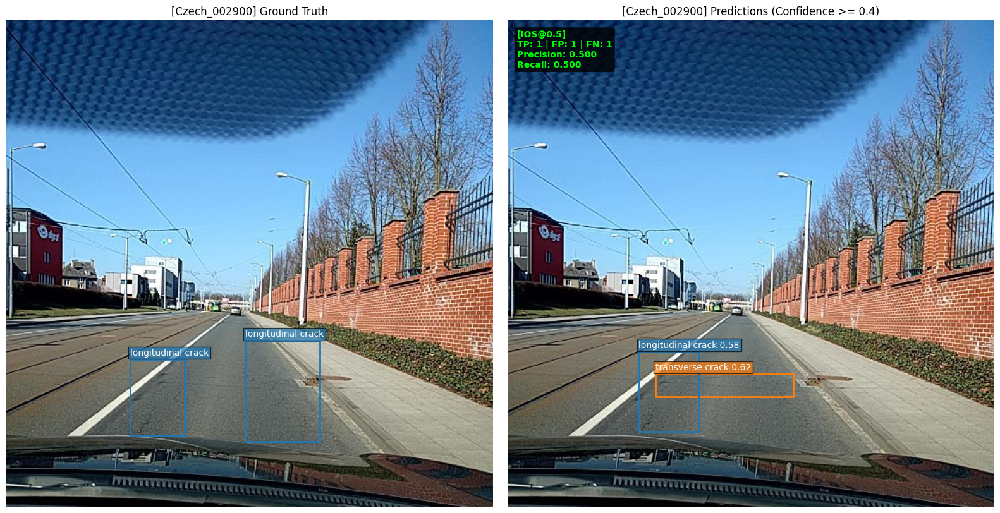


--- Metrics for image: [India_008128]  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |    4 |       2 |    0 |    2 |    4 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


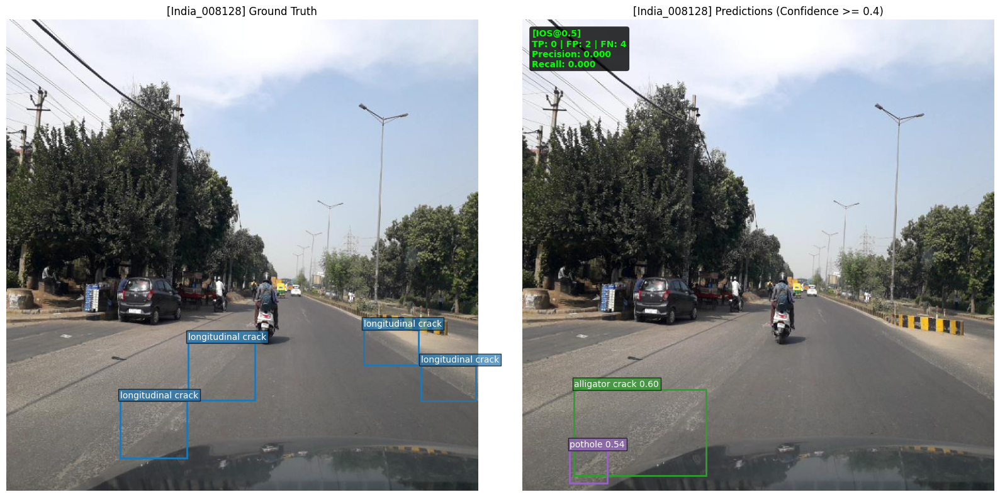


--- Metrics for image: [India_003379]  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |    0 |       1 |    0 |    1 |    0 |           0 |        0 |
+------------------+------+---------+------+------+------+-------------+----------+


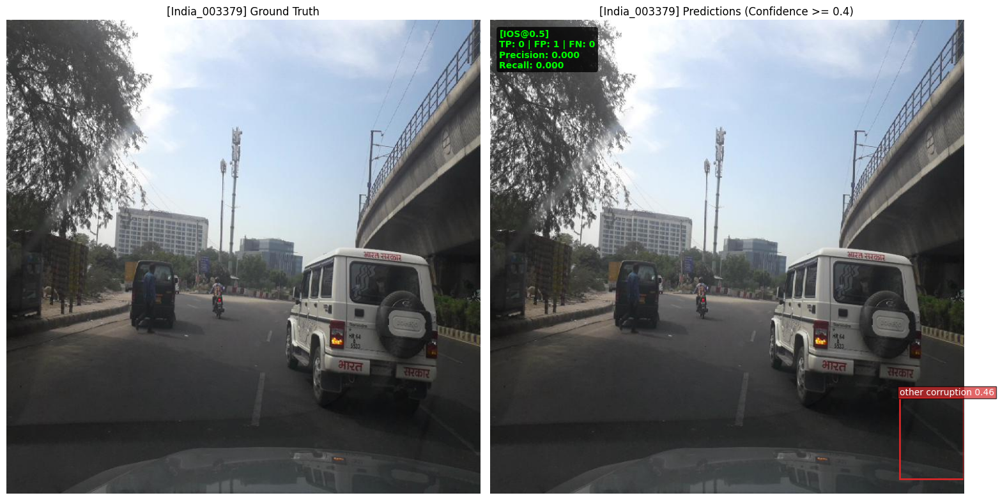


--- Metrics for image: [Japan_004881]  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |    3 |       4 |    3 |    1 |    0 |        0.75 |        1 |
+------------------+------+---------+------+------+------+-------------+----------+


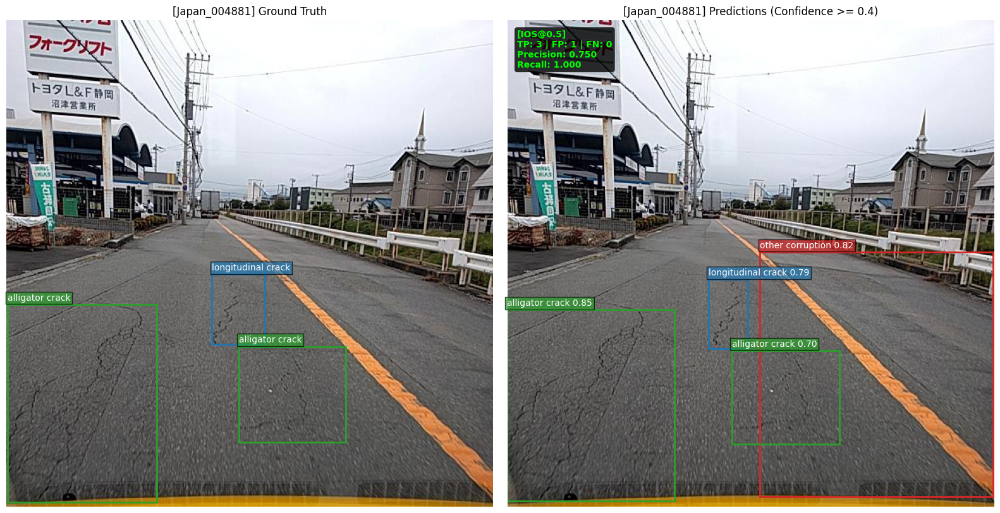

In [31]:
poor_localization = dataset_evaluator.filter(
    class_names=["longitudnal crack","transverse crack","alligator crack","other corruption","pothole"],
    model_confidence_threshold=0.4,
    metric="ios",
    eq="<",
    class_confidence_threshold=0.65
)
poor_localization.plot(num_samples=5, model_confidence_threshold=0.4, show=True, show_stats=True)

Filter matched 496 / 5758 images.

--- Metrics for image: [United_States_003356]  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |    2 |       6 |    2 |    4 |    0 |      0.3333 |        1 |
+------------------+------+---------+------+------+------+-------------+----------+


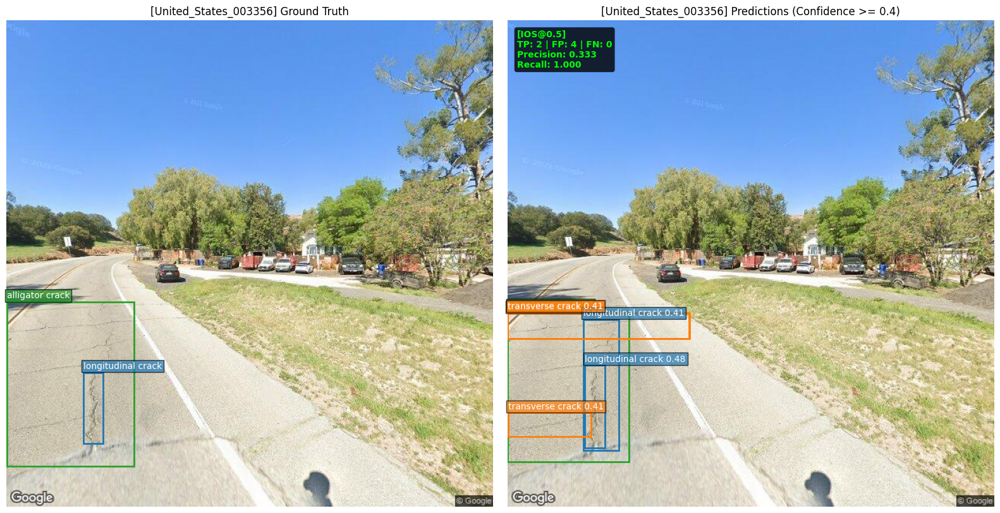


--- Metrics for image: [India_003013]  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |    8 |      11 |    7 |    4 |    1 |      0.6364 |    0.875 |
+------------------+------+---------+------+------+------+-------------+----------+


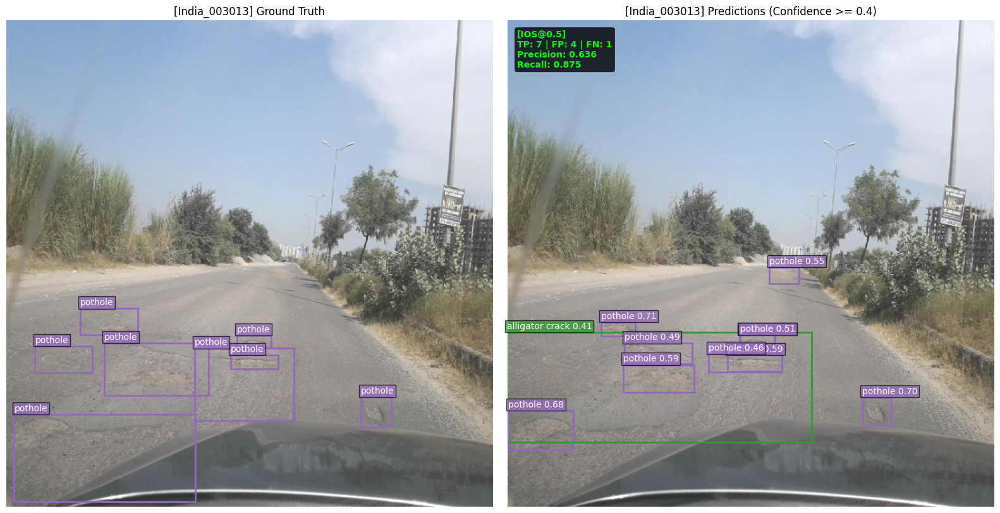


--- Metrics for image: [Japan_000650]  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |    6 |       7 |    4 |    3 |    2 |      0.5714 |   0.6667 |
+------------------+------+---------+------+------+------+-------------+----------+


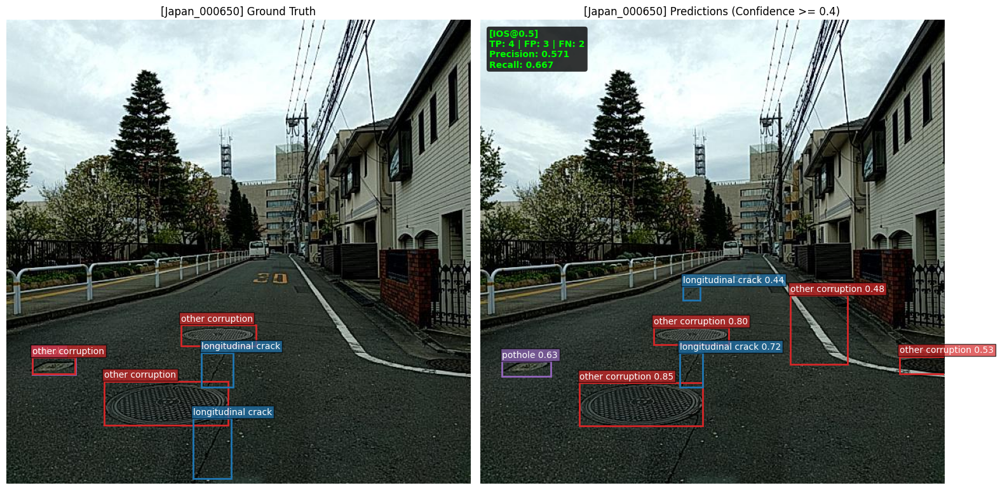


--- Metrics for image: [United_States_004044]  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |    1 |       3 |    1 |    2 |    0 |      0.3333 |        1 |
+------------------+------+---------+------+------+------+-------------+----------+


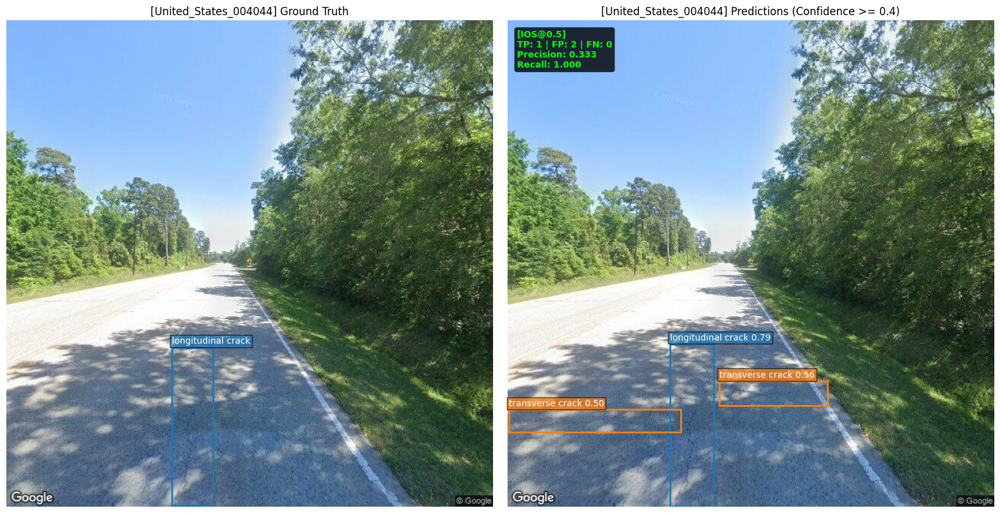


--- Metrics for image: [Norway_002153]  (Conf: 0.4, IOS@0.5) ---
+------------------+------+---------+------+------+------+-------------+----------+
|   Conf_Threshold |   GT |   Preds |   TP |   FP |   FN |   Precision |   Recall |
+==================+======+=========+======+======+======+=============+==========+
|              0.4 |   14 |      19 |   10 |    9 |    4 |      0.5263 |   0.7143 |
+------------------+------+---------+------+------+------+-------------+----------+


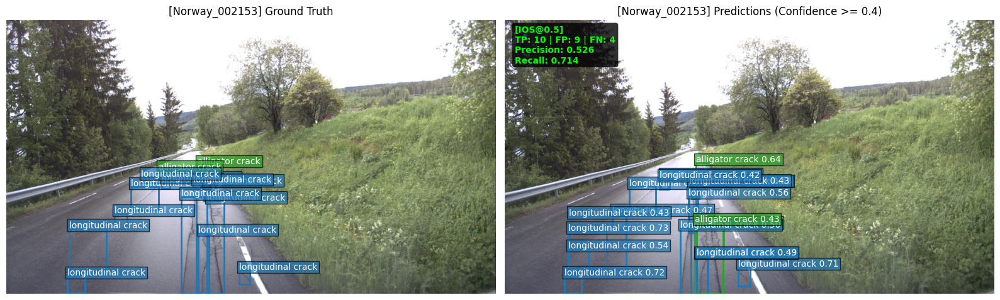

In [32]:
fragmented_preds = dataset_evaluator.filter(
    class_names=["longitudnal crack","transverse crack","alligator crack","other corruption","pothole"],
    model_confidence_threshold=0.4,
    metric="fp",
    eq=">=",
    class_confidence_threshold=2
)
fragmented_preds.plot(num_samples=5, model_confidence_threshold=0.4, show=True, show_stats=True)